# 03 AI运维 - 项目部署上线


## 本篇资料与安全说明

本篇对应 **AI运维8小时精华版 → 3-0基础带你入行AI Linux运维_项目部署上线.pdf**，共 **122 页**。课件前半部分以“中州养老（zzyl）”为例，练习三节点部署；后半部分介绍 ChatGLM-6B 私有化智能客服的 GPU、Anaconda 和模型环境准备。

资料来源：[课程网盘](https://pan.baidu.com/s/1piPE1VDdCBoKDeGf-34QPA?pwd=1234)，提取码 `1234`。本篇依据全部 122 页课件文字与页面预览整理，重复封面、总结和作业页归入相应章节，不是视频逐字稿。

**安全提醒：** 课件第 9 页展示了测试、生产环境的 AccessKey、Secret 和百度千帆信息。本文不复制任何真实凭据；如果这些凭据曾被公开、截图或提交到代码库，应立即在云平台禁用并重新生成。生产配置使用环境变量、密钥管理服务或最小权限 RAM 用户，绝不要把 Secret 写进 Notebook、Git、聊天记录或前端代码。

学习路线：项目认识 → 三节点规划 → ECS 初始化 → MySQL 与数据 → Redis → OSS → 百度千帆 → Java 后端 → Nginx 前端 → 上线检查 → ChatGLM-6B 服务器与 Python 环境。

| 主题 | 课件页码 | 目标 |
| --- | --- | --- |
| 项目与架构 | 2-10 | 识别管理后台、家属端、三台节点及外部服务 |
| 节点初始化 | 11-17 | 准备 ECS、远程连接、修改主机名 |
| MySQL 与业务数据 | 18-28 | 安装数据库、导入 SQL、校验表 |
| Redis | 29-32 | 安装、配置、启动并测试缓存服务 |
| OSS 与千帆 | 33-55 | 创建对象存储、接入图片和体检报告分析 |
| 后端与前端 | 56-85 | 运行 Jar、screen 托管、Nginx 反向代理静态前端 |
| 私有化大模型准备 | 86-122 | GPU 服务器、驱动、Anaconda、ChatGLM-6B 环境 |


## 一、项目认识与部署架构

### 1.1 中州养老项目做什么

**原课依据：第 2-5 页。** 中州养老是面向养老院的管理软件，覆盖来访、入住与退住、在住管理、服务记录、财务等业务。系统分为两端：

- **管理后台**：养老院员工在浏览器中使用，处理入住、退住、服务记录和 AI 体检报告分析。
- **家属端**：老人家属通过微信小程序查看老人信息、缴费、下订单和使用智能客服。

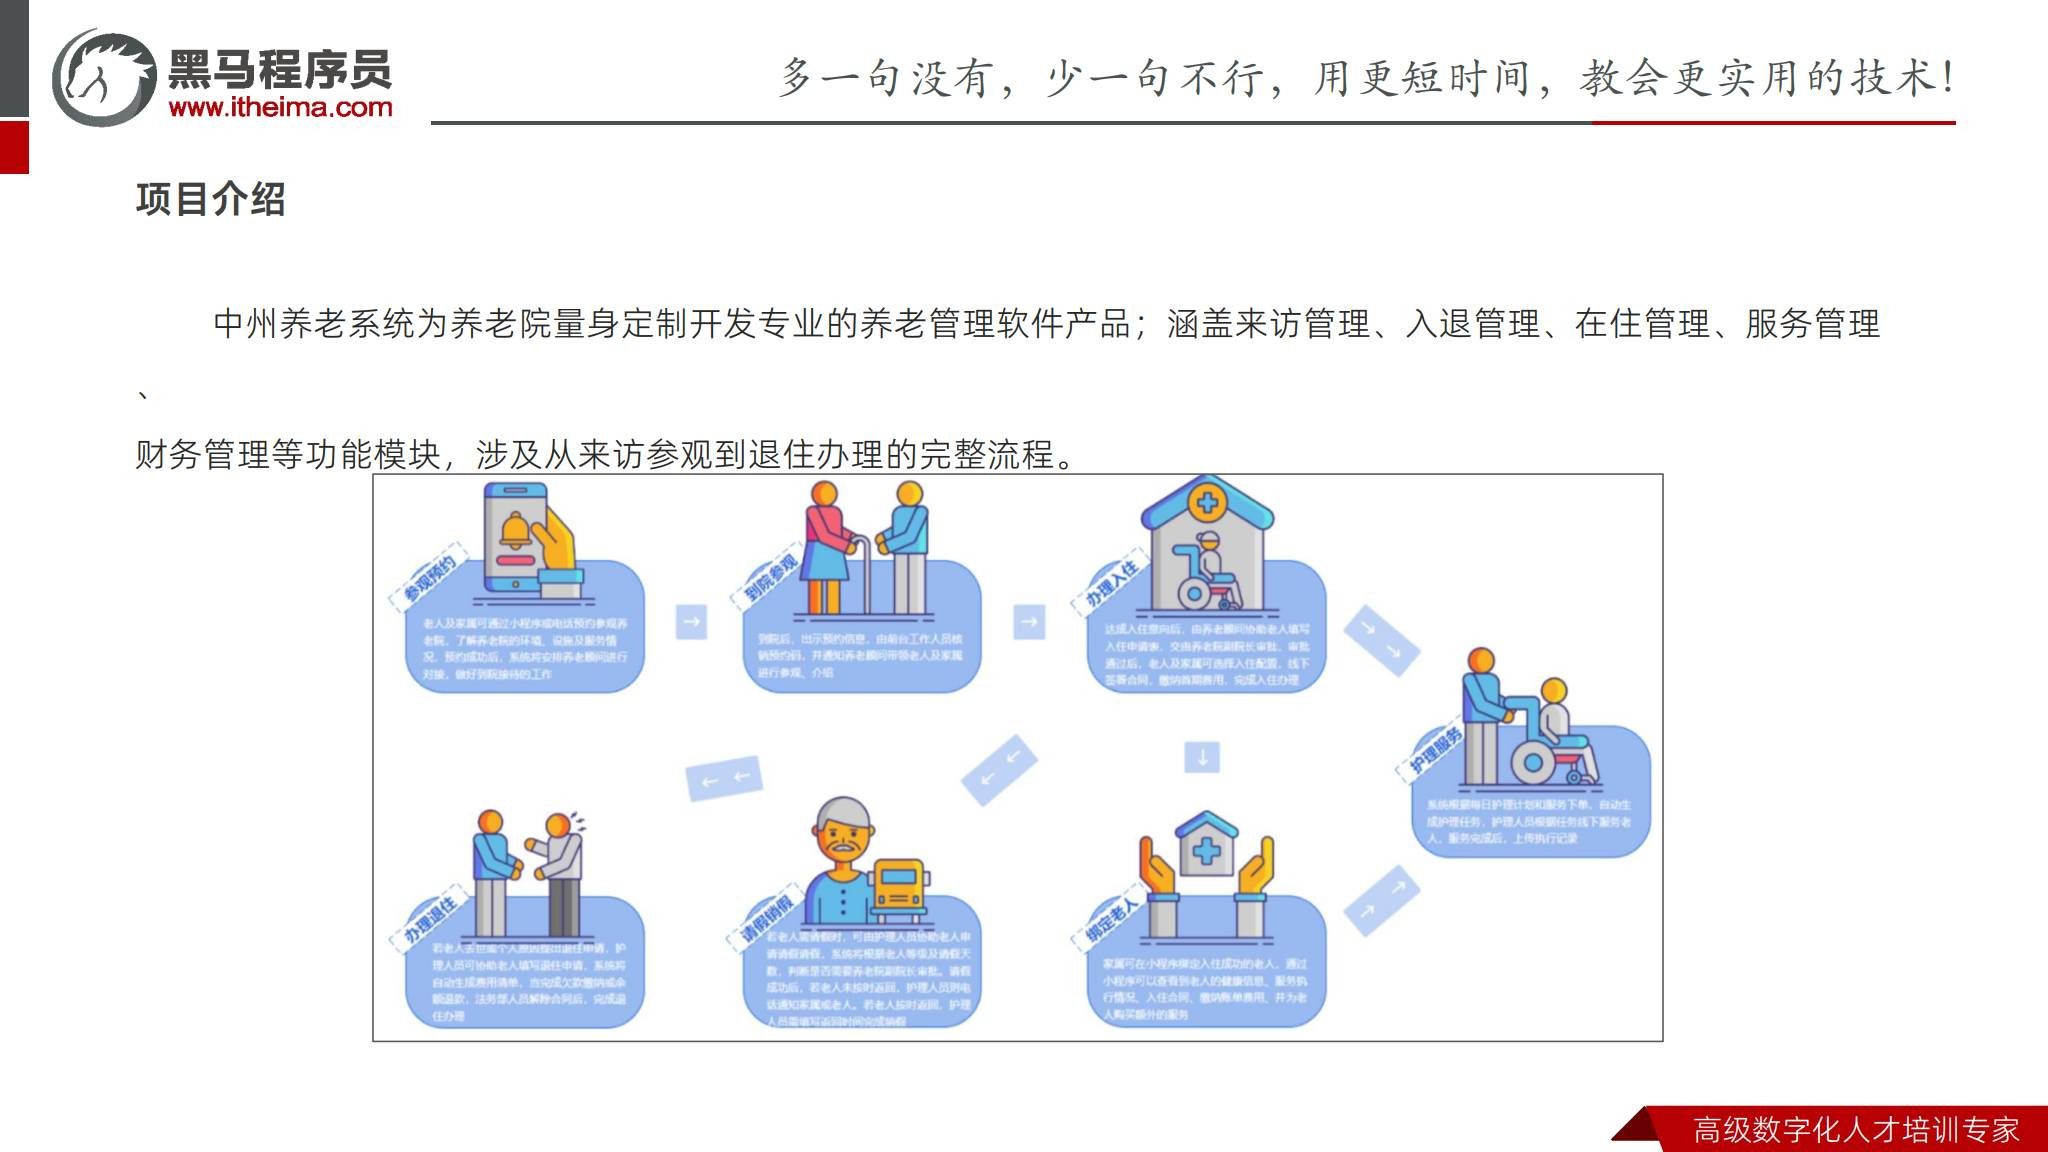

项目原型地址和密码只用于课件演示；实际工作中应按团队权限访问，不把原型口令写入公开笔记。

### 1.2 三节点架构

**原课依据：第 6-10 页。** 课程规划三台 ECS 节点：

| 节点 | 部署内容 | 作用 |
| --- | --- | --- |
| node1 | MySQL、Redis | 保存业务数据、提供缓存/高速读写 |
| node2 | 后端 Jar | 运行 Java 编译后的服务，访问 node1 |
| node3 | Nginx、前端 dist | 提供静态页面，并把 `/prod-api/` 转发给 node2 |

外部服务包括微信公众平台、阿里云 OSS 和百度千帆。浏览器访问 node3；小程序调用后台 API；Nginx 负责静态文件和反向代理，后端再访问数据库、Redis、OSS 和千帆。

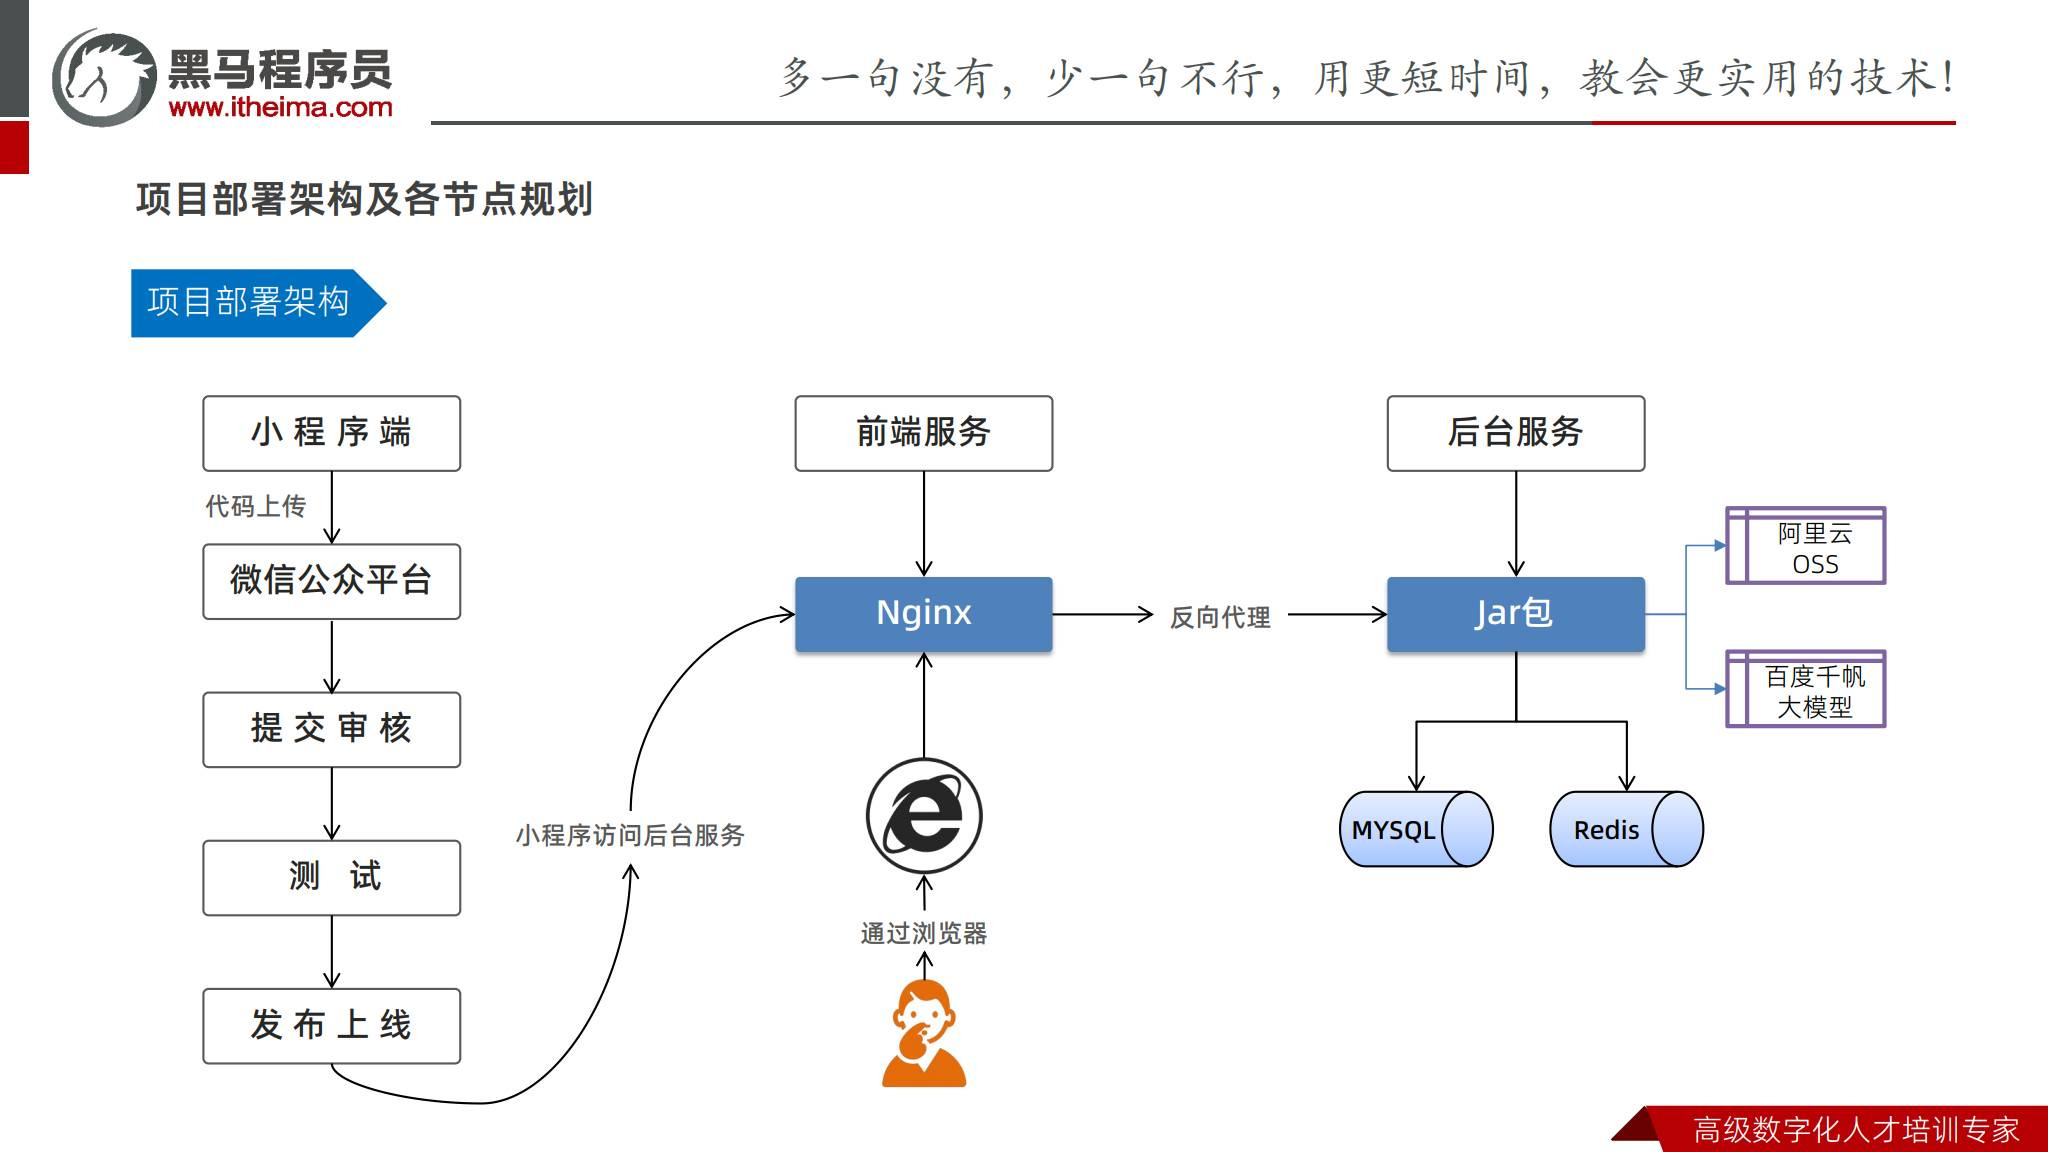

```text
微信小程序 / 浏览器
          |
       node3: Nginx + dist
          |  /prod-api/ 反向代理
       node2: Java Jar
          |
       node1: MySQL + Redis
          |
  阿里云 OSS / 百度千帆 / 微信平台
```

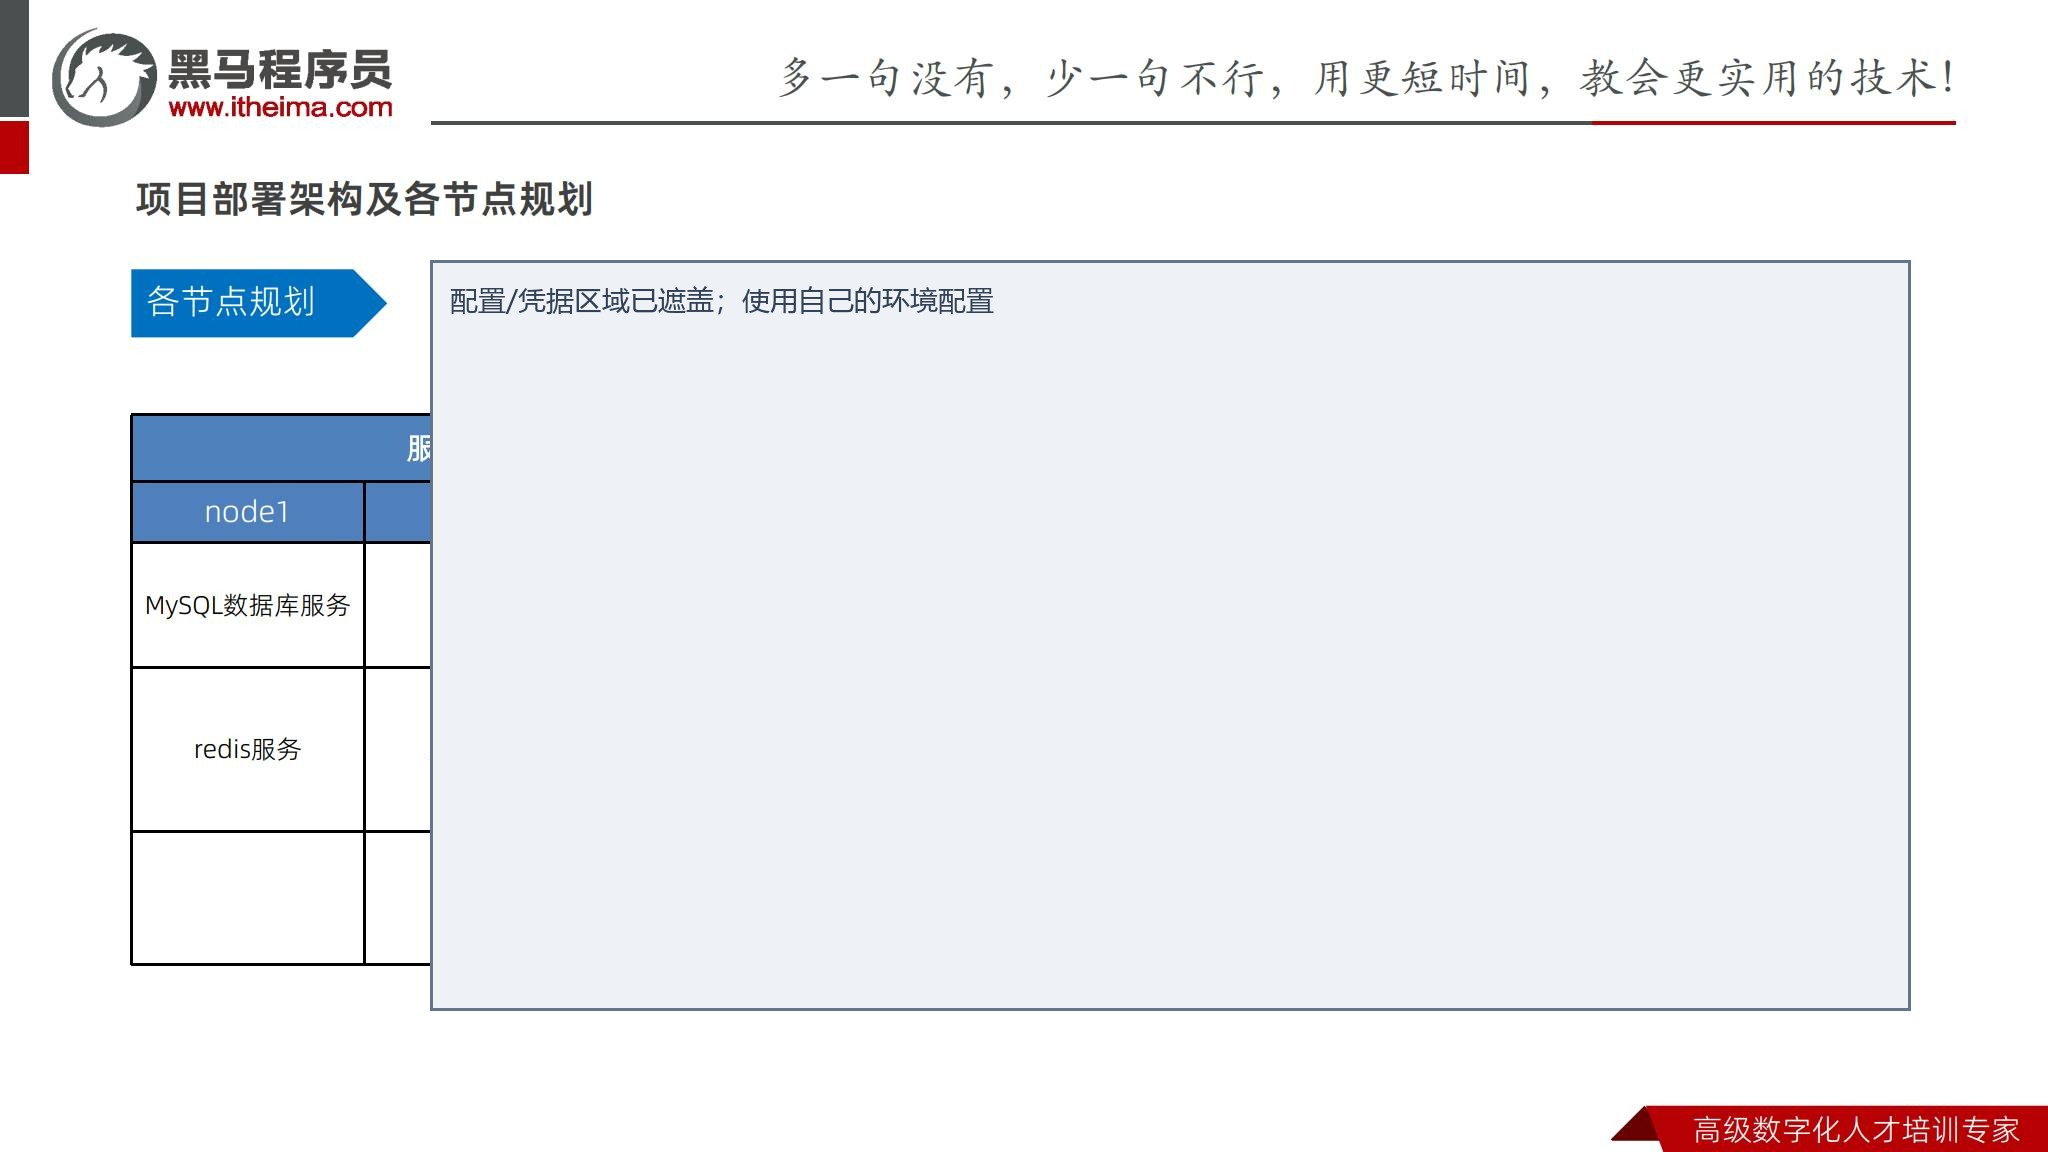

**整理补充：** 三节点只是课程练习的清晰边界；生产环境还应考虑私网通信、负载均衡、高可用、备份、监控、日志、最小权限和安全组。不要把课件中的示例 IP、账号或端口直接照搬到真实环境。

### 1.3 节点规划复盘

课件总结的关键结论是：需要 3 个节点，数据服务集中在 node1，后端在 node2，前端 Nginx 在 node3，并开通 OSS 和千帆。ECS 尽量放在同一可用区，网络延迟更稳定；练习建议从 2 核 4 GB 起步，生产容量要根据压测和监控调整。


## 二、ECS 节点初始化

### 2.1 申请和连接服务器

**原课依据：第 11-17 页。** 练习步骤：

1. 在阿里云申请三台 ECS，选择同一可用区，并为每台设置可识别的名称。
2. 用 SSH 或 MobaXterm 连接三个公网地址。公网 IP 可能在释放并重新分配后变化，连接配置应以控制台当前值为准。
3. 仅在安全组放行必要端口。SSH 不建议对全网开放，数据库和 Redis 端口更不应直接暴露公网。
4. 分别设置主机名：

```bash
# 在第一台执行
sudo hostnamectl set-hostname node1.itcast.cn

# 在第二台执行
sudo hostnamectl set-hostname node2.itcast.cn

# 在第三台执行
sudo hostnamectl set-hostname node3.itcast.cn
hostnamectl --static
```

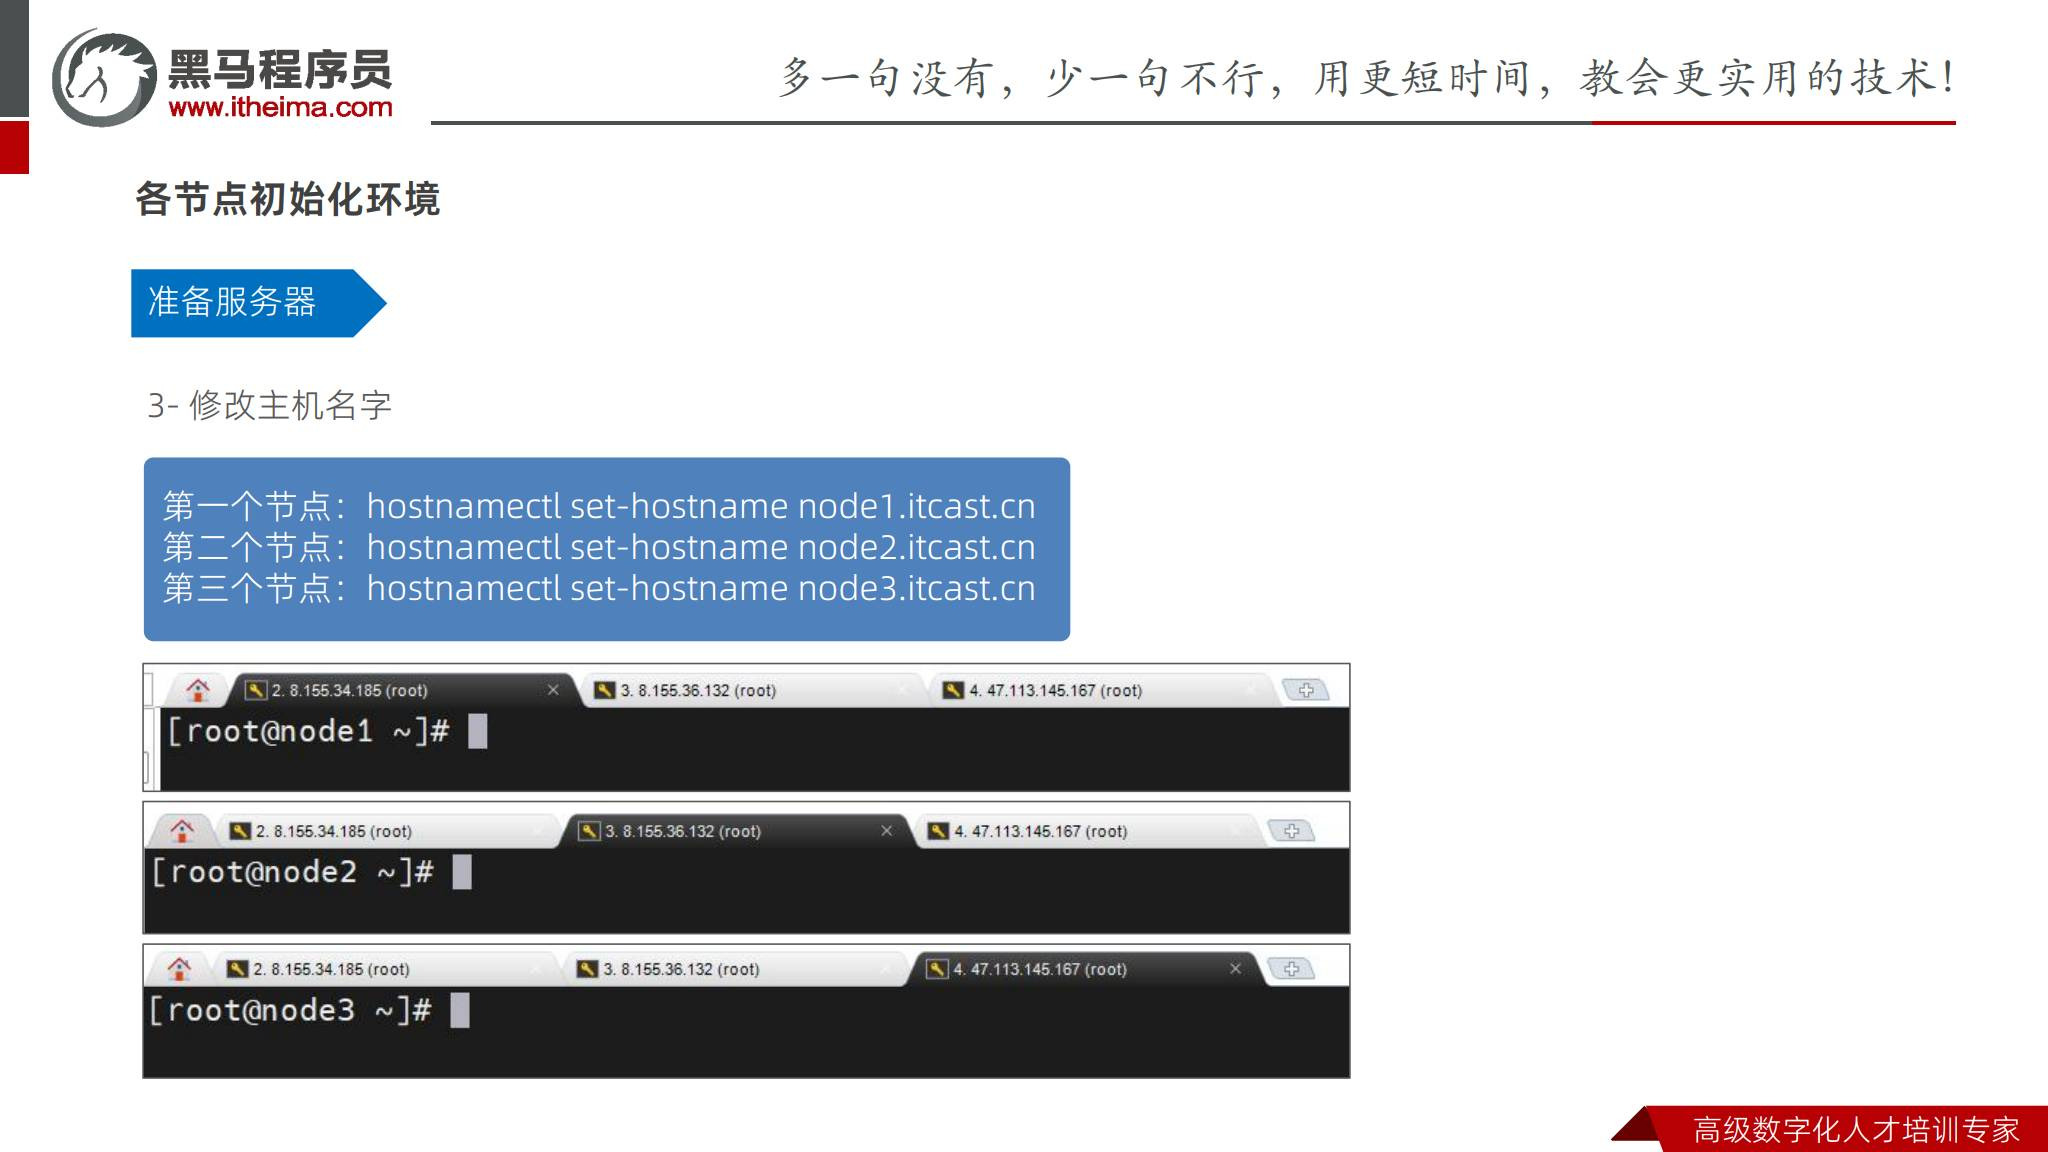

**整理补充：** `hostnamectl` 修改的是系统主机名，不会自动建立 DNS 或 `/etc/hosts` 解析。三台机器之间若用名称通信，应配置私网 DNS 或经过核对的 `/etc/hosts`；不要用会变化的公网 IP 作为长期服务发现方案。

### 2.2 初始化检查表

在继续安装组件前，每台节点都应确认：

```bash
whoami
hostnamectl --static
ip -br address
df -h
free -h
timedatectl
```

检查系统版本、磁盘空间、内存、时间同步、默认用户和 sudo 权限。把三台机器的信息记录到私有资产表，不写入公开 Notebook。

### 2.3 作业与验收

本节作业是完成三台 ECS 申请和主机名修改。验收标准：三台机器均可通过受控 SSH 登录；主机名分别为 node1/node2/node3；安全组只开放设计好的端口；三台机器在同一网络规划中。


## 三、MySQL 安装与业务数据导入

### 3.1 MySQL 的角色

**原课依据：第 18-22 页。** MySQL 是关系型数据库，保存用户、老人、订单等结构化业务数据。课程将安装分成六步：安装仓库、安装软件、启动服务、完成配置、登录测试、按需要配置防火墙。

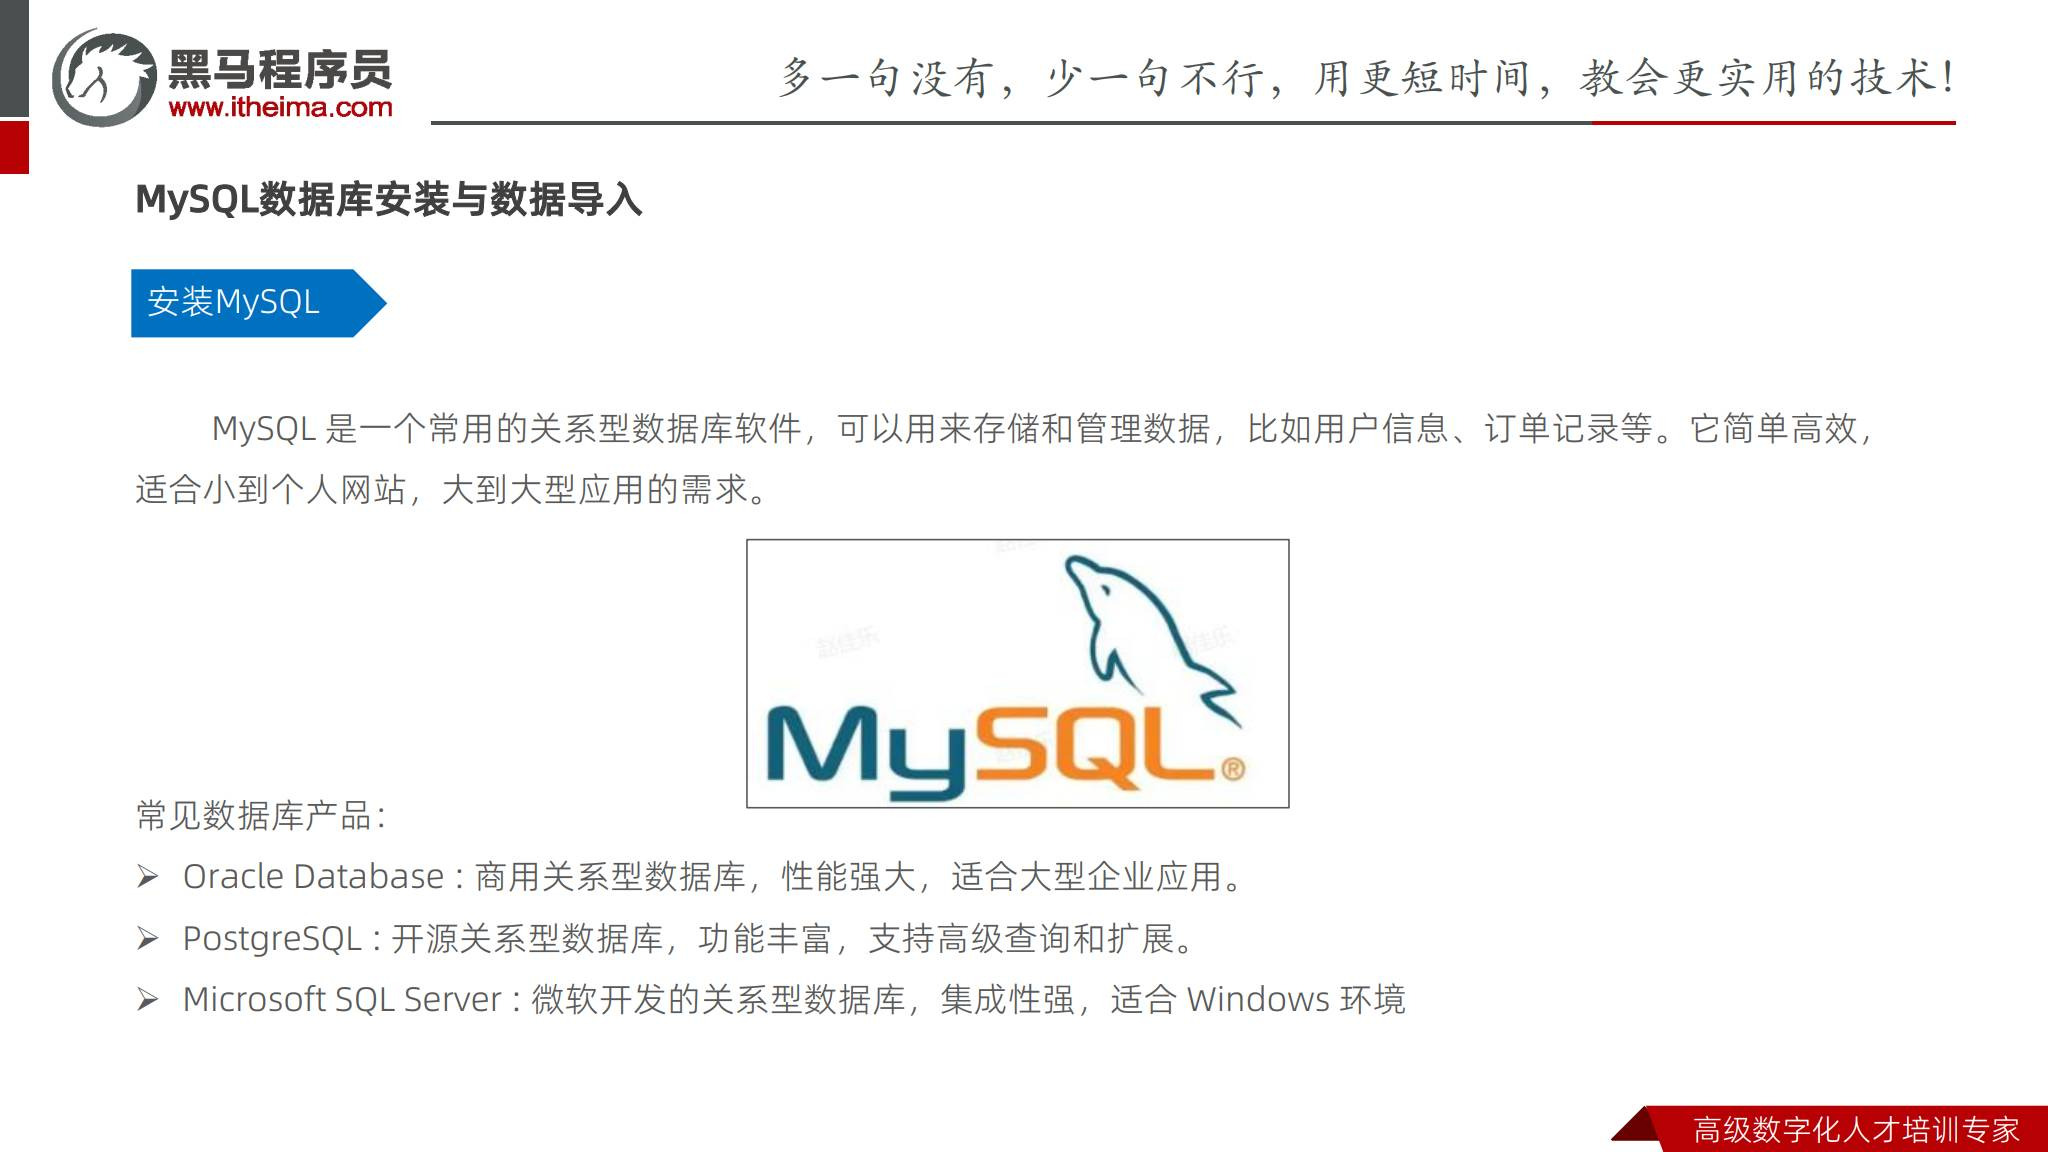

课程给出的安装文档在飞书链接中。不同 Linux 发行版和 MySQL 大版本的仓库地址、初始化命令可能不同，应以当前系统和官方文档为准，不把某一条 `dnf` 命令当成所有环境的通用答案。

### 3.2 服务状态与最小验证

下面是安装完成后的通用检查思路，具体包名按发行版调整：

```bash
sudo systemctl enable --now mysqld
sudo systemctl status mysqld --no-pager
mysql --version
sudo ss -lntp | grep ':3306'
```

首次配置应设置强密码、删除匿名用户和测试库、限制监听地址，并确认 root 远程登录策略。生产环境不应使用课件截图里的示例密码；密码应由安全渠道生成和保存。

### 3.3 导入项目 SQL

**原课依据：第 23-28 页。** 课件将 SQL 上传到 `/opt/zzyl/sql`，再导入 `ry-zzyl.sql`。路径和文件名需先以实际交付包为准，示例流程如下：

```bash
sudo install -d -m 0750 /opt/zzyl/sql
cd /opt/zzyl/sql
# 由受控文件传输工具上传 ry-zzyl.sql
sha256sum ry-zzyl.sql

# 使用交互式密码输入，避免密码出现在 shell 历史中
mysql -u root -p < ry-zzyl.sql
```

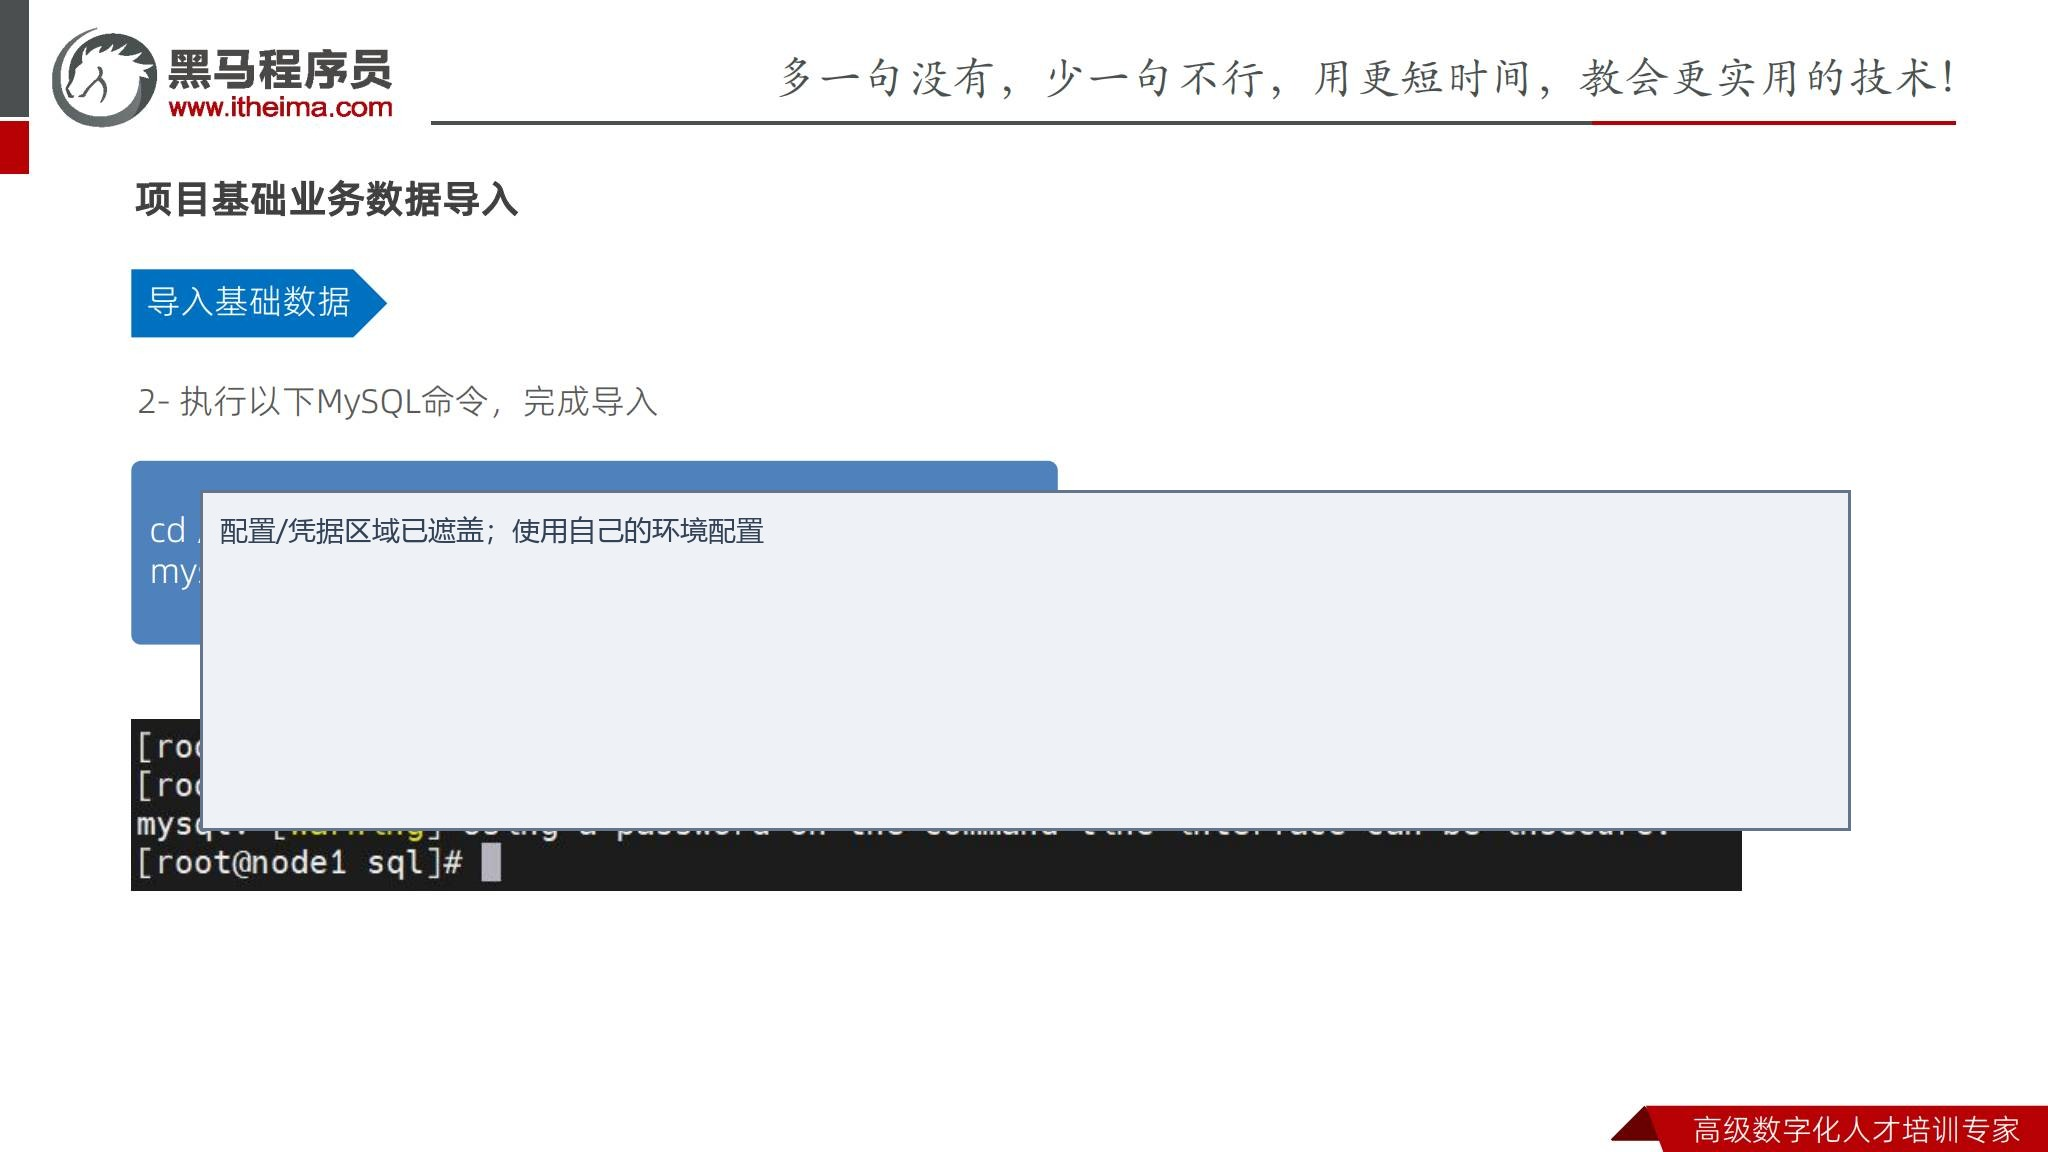

核对数据库和表：

```bash
mysql -u root -p -e 'SHOW DATABASES;'
mysql -u root -p -e 'USE `ry-zzyl`; SHOW TABLES;'
```

**整理补充：** 课件命令把密码直接写在 `-p` 后面，容易进入进程列表或 shell 历史；本笔记改为交互式输入。若数据库名含连字符，使用反引号包围。导入前备份现有数据库，并核对 SQL 来源、哈希和目标字符集。

### 3.4 数据库上线验收

- mysqld 已启用并能在重启后自动恢复。
- 应用专用账号只拥有目标库所需权限，不让应用长期使用 root。
- node2 能通过私网访问 node1 的 3306，公网无法直接访问。
- 导入后表数量、关键基础数据和字符集符合项目预期。
- 备份恢复演练成功，错误日志可查看。


## 四、Redis 安装与验证

### 4.1 Redis 的角色

**原课依据：第 29-32 页。** Redis 把数据放在内存中，适合缓存、实时数据、计数和消息队列等快速读写场景。课程将流程概括为下载、配置、启动、测试和按需开放防火墙。

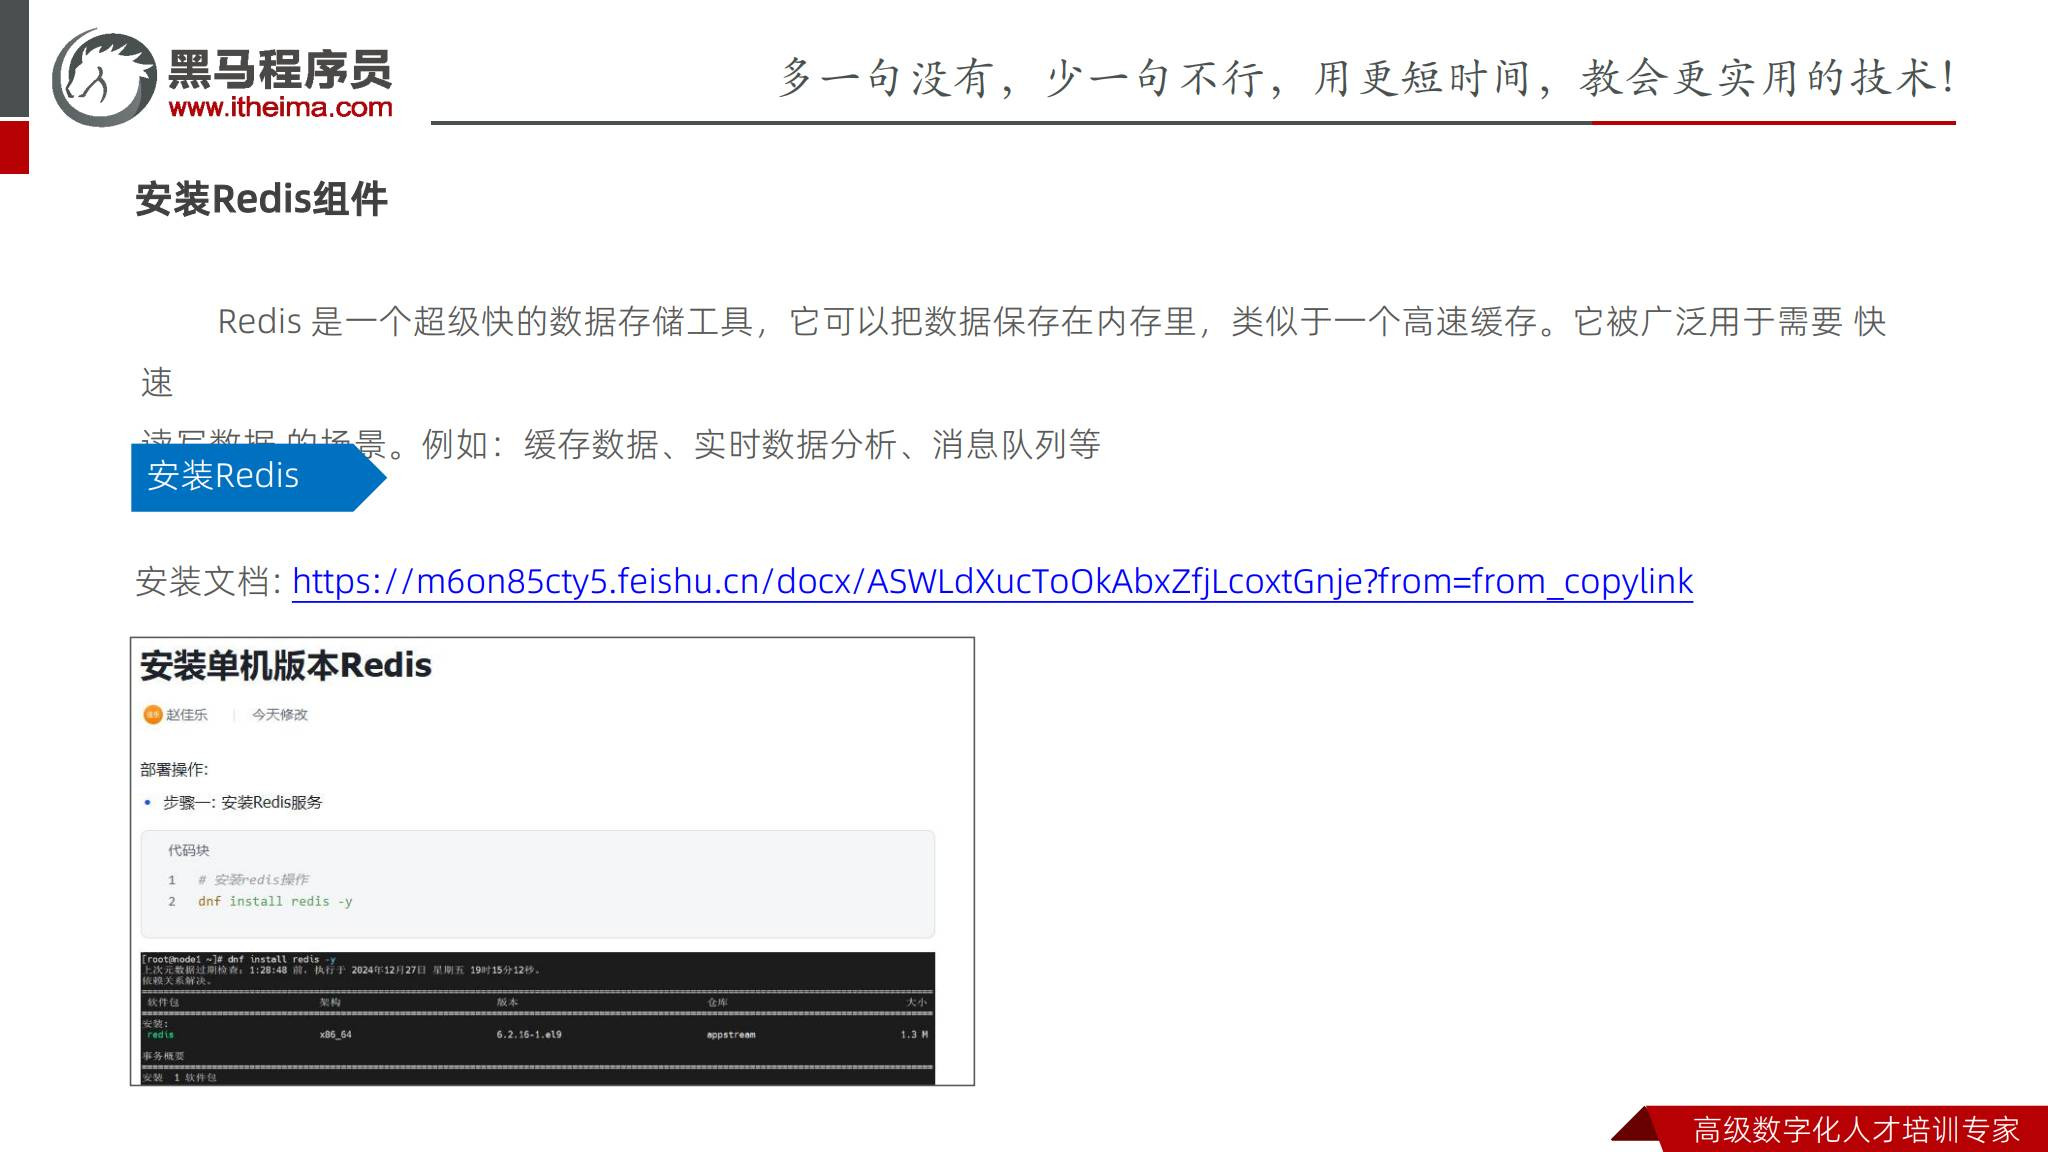

### 4.2 安装后的通用检查

具体安装命令以课程提供的文档和系统仓库为准，完成后可检查：

```bash
sudo systemctl enable --now redis
sudo systemctl status redis --no-pager
redis-cli ping
sudo ss -lntp | grep ':6379'
```

正常的 `redis-cli ping` 应返回 `PONG`。如果服务名是 `redis-server`，以 `systemctl list-unit-files | grep -i redis` 查实际单元名。

### 4.3 生产安全配置

Redis 不应直接暴露公网。配置监听私网地址、访问认证或 ACL、合理的持久化策略和内存淘汰策略，并用安全组限制 node2 到 node1 的访问。缓存数据丢失是否可接受，要由业务决定；不要默认把 Redis 当作永久数据库。

```bash
redis-cli -h <private-ip> -a '<password>' ping
```

命令行中的密码可能进入历史记录，正式排查优先使用 ACL、受控环境变量或交互方式，并在日志和工单中打码。


## 五、阿里云 OSS：对象存储

### 5.1 OSS 的用途

**原课依据：第 33-42 页。** OSS 是云端对象存储，用于图片、视频、文档、备份等非结构化文件。养老项目可把老人资料、服务图片或报告附件放在 OSS，数据库只保存对象键、元数据和业务关联。

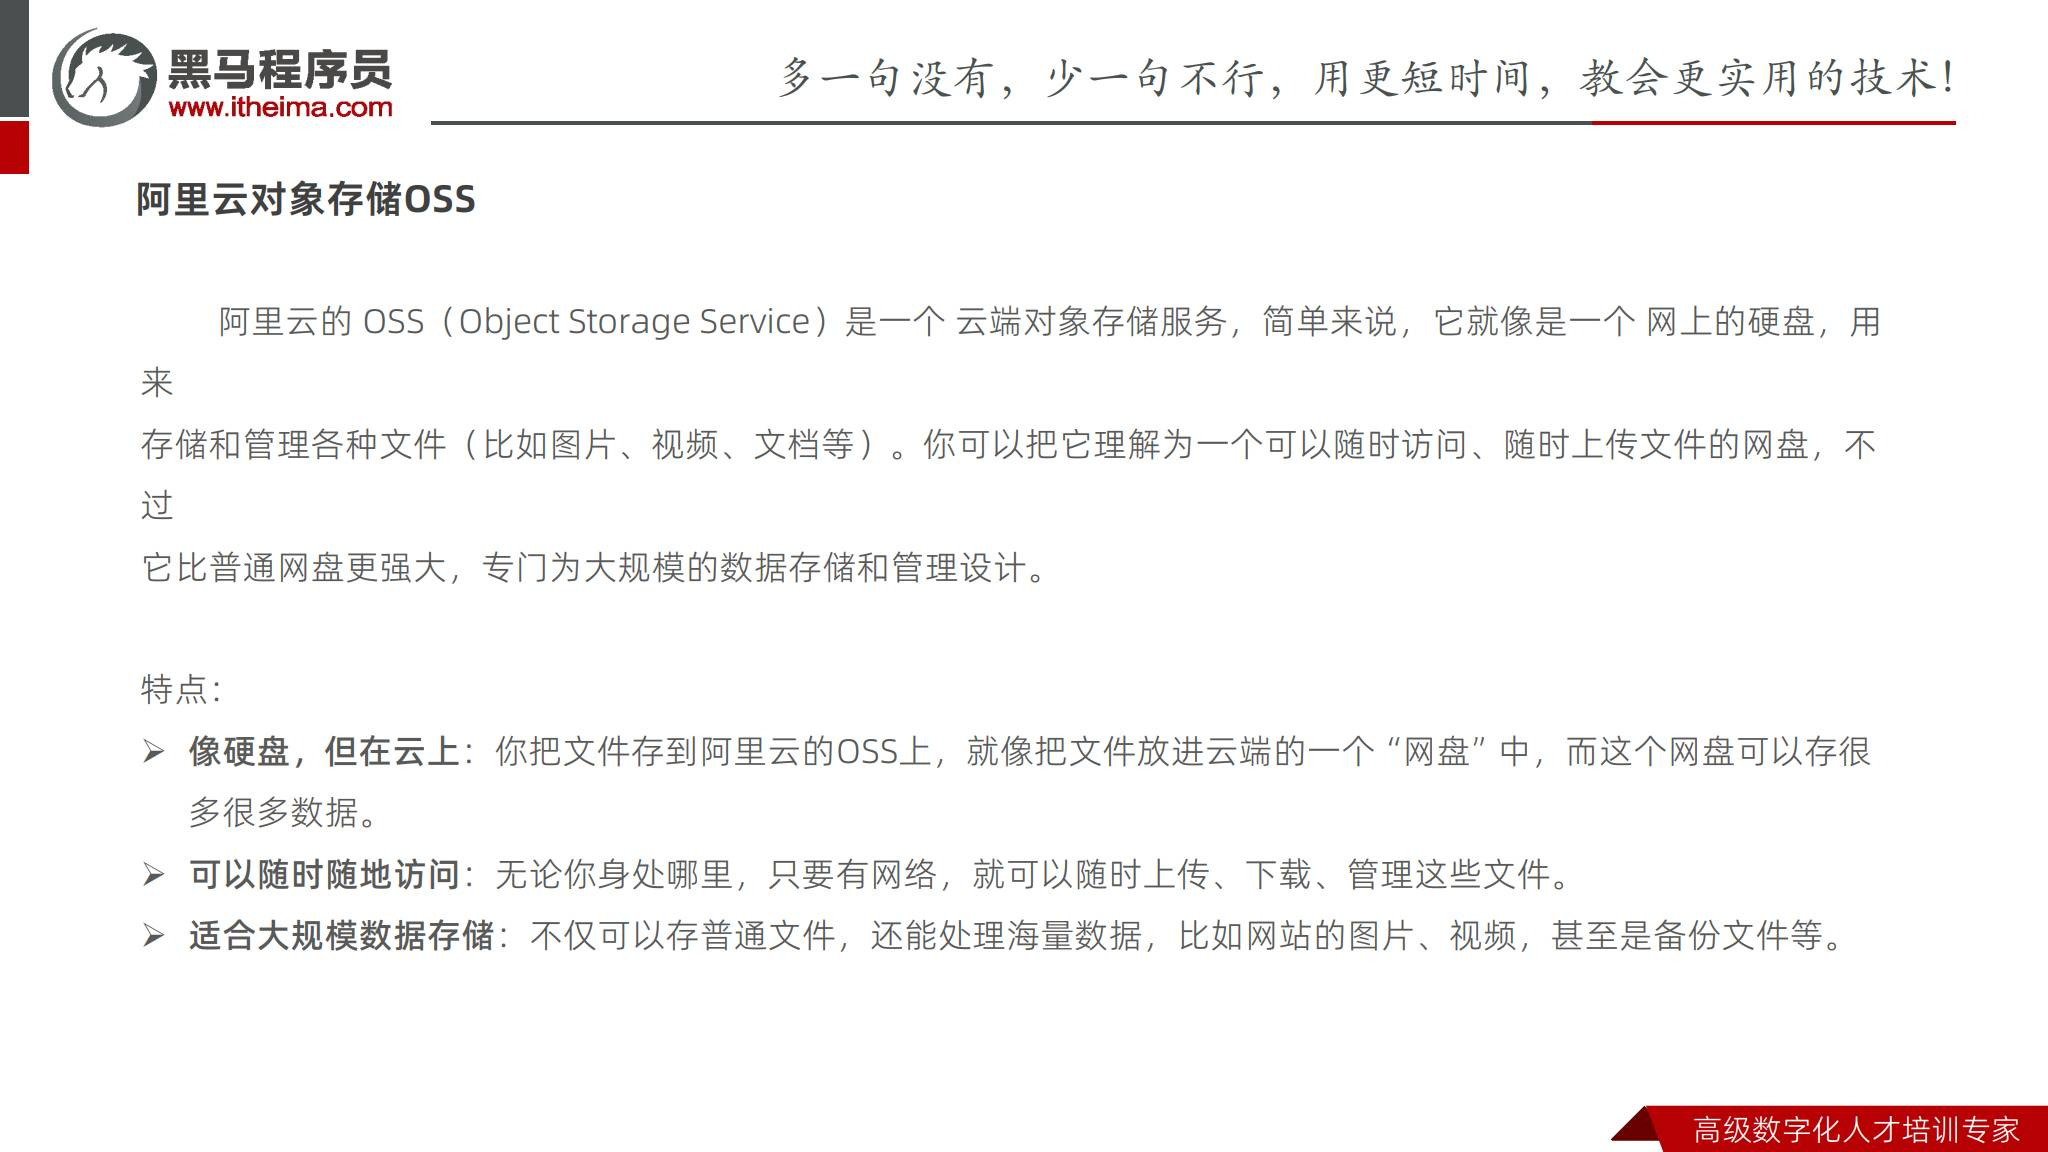

对象存储和本地磁盘不同：对象通常通过 bucket、key 和 endpoint 定位；权限、生命周期、版本、地域和访问域名都会影响应用代码。

### 5.2 开通和创建 bucket

课程流程：开通 OSS → 进入对象存储控制台 → 创建 bucket → 配置访问策略 → 生成 AccessKey。

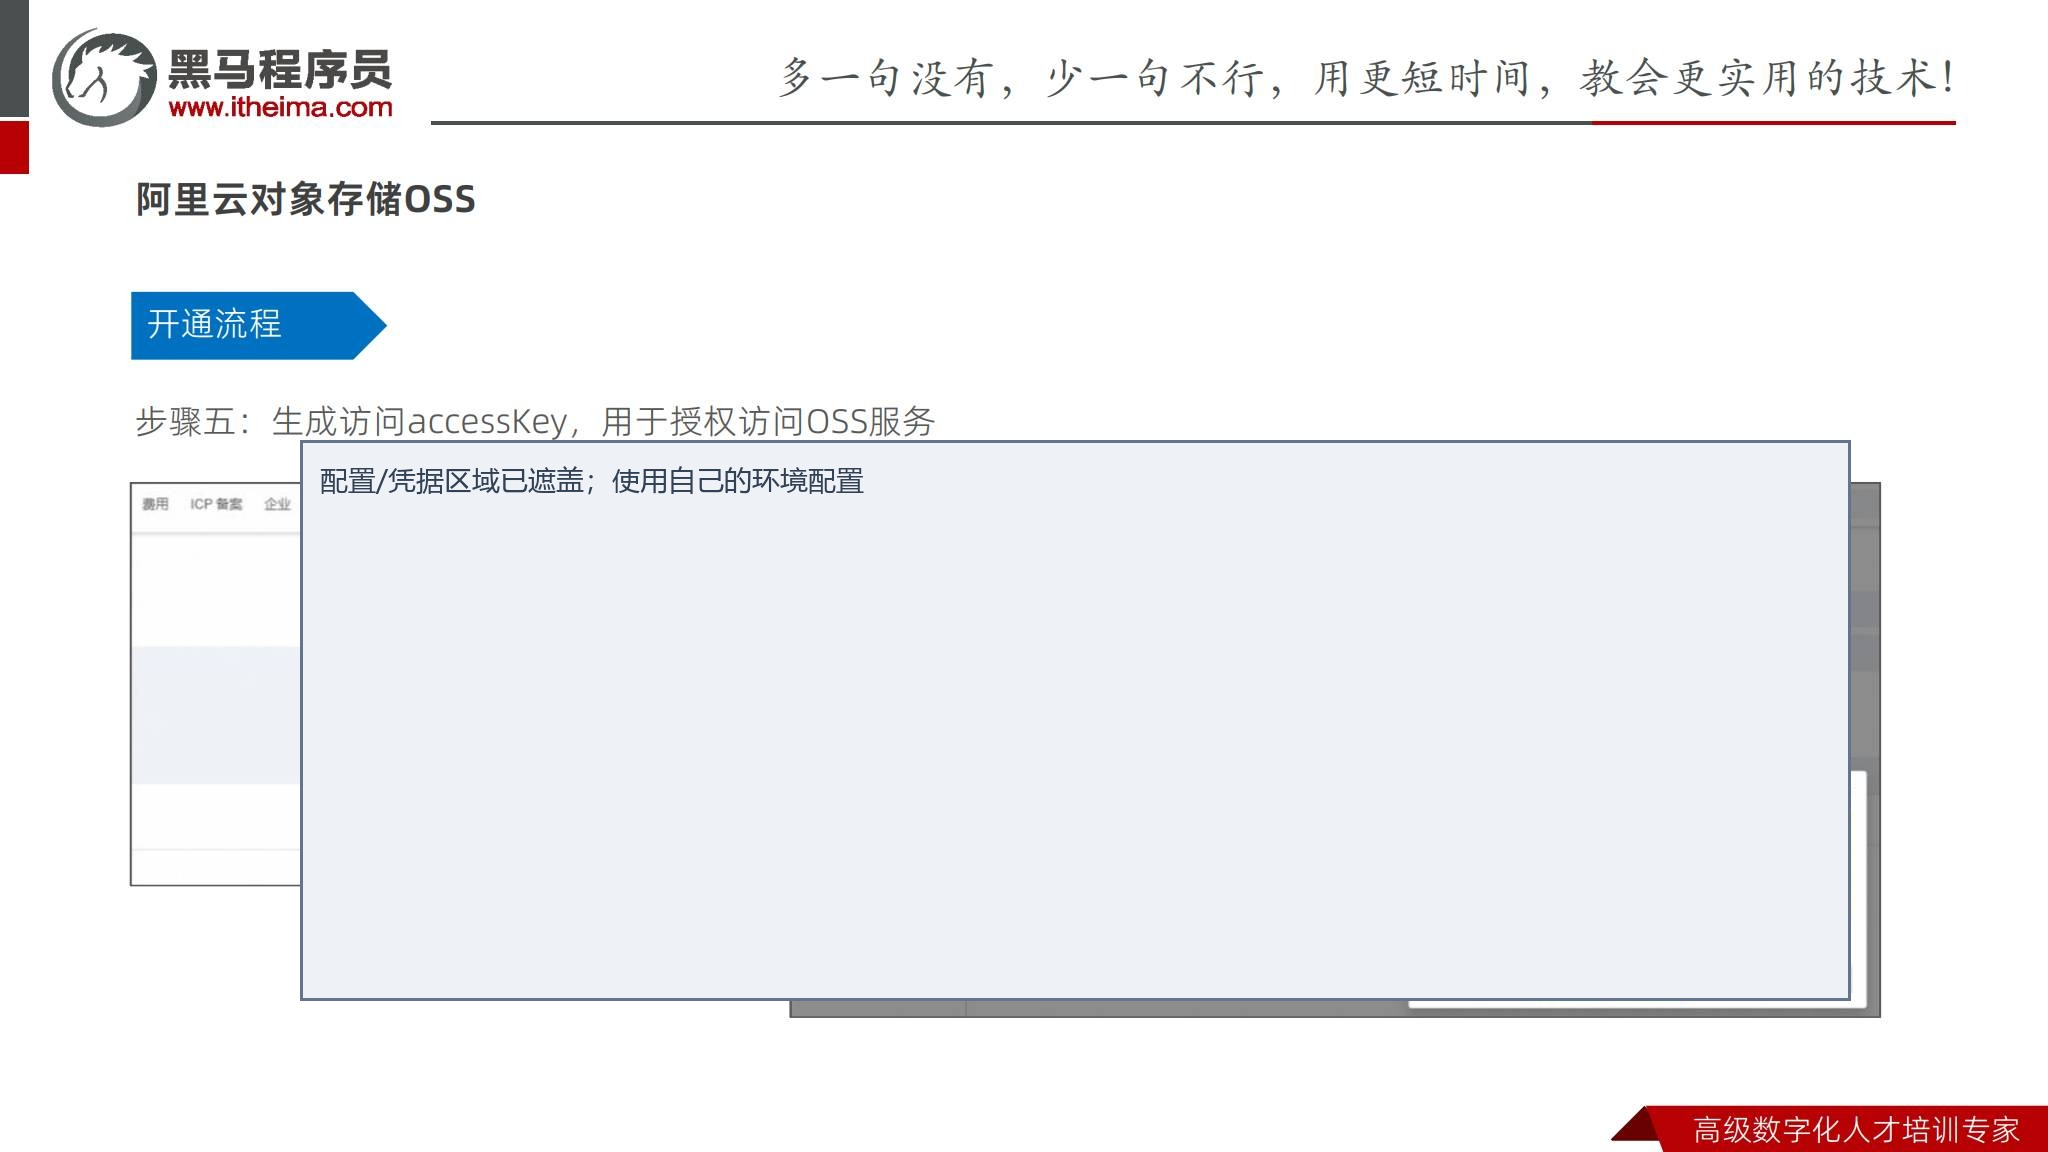

建议按以下原则完成：

1. bucket 名称全局唯一，并选择与应用及 ECS 接近的地域。
2. 默认设置私有读，应用通过临时凭证或后端签名 URL 提供访问。
3. 若必须公开访问，只公开无敏感内容的前缀，并配置防盗链、HTTPS、生命周期和日志。
4. 使用 RAM 子账号和最小权限策略，只允许目标 bucket 的必要操作。
5. AccessKey Secret 只在生成时安全保存，之后不出现在截图、代码和 Notebook。

### 5.3 项目接入 OSS

**原课依据：第 43-46 页。** 课程要求打开生产环境配置文件，修改授权 ID、授权 Secret 和 bucket 名称，再把文件放回服务器。

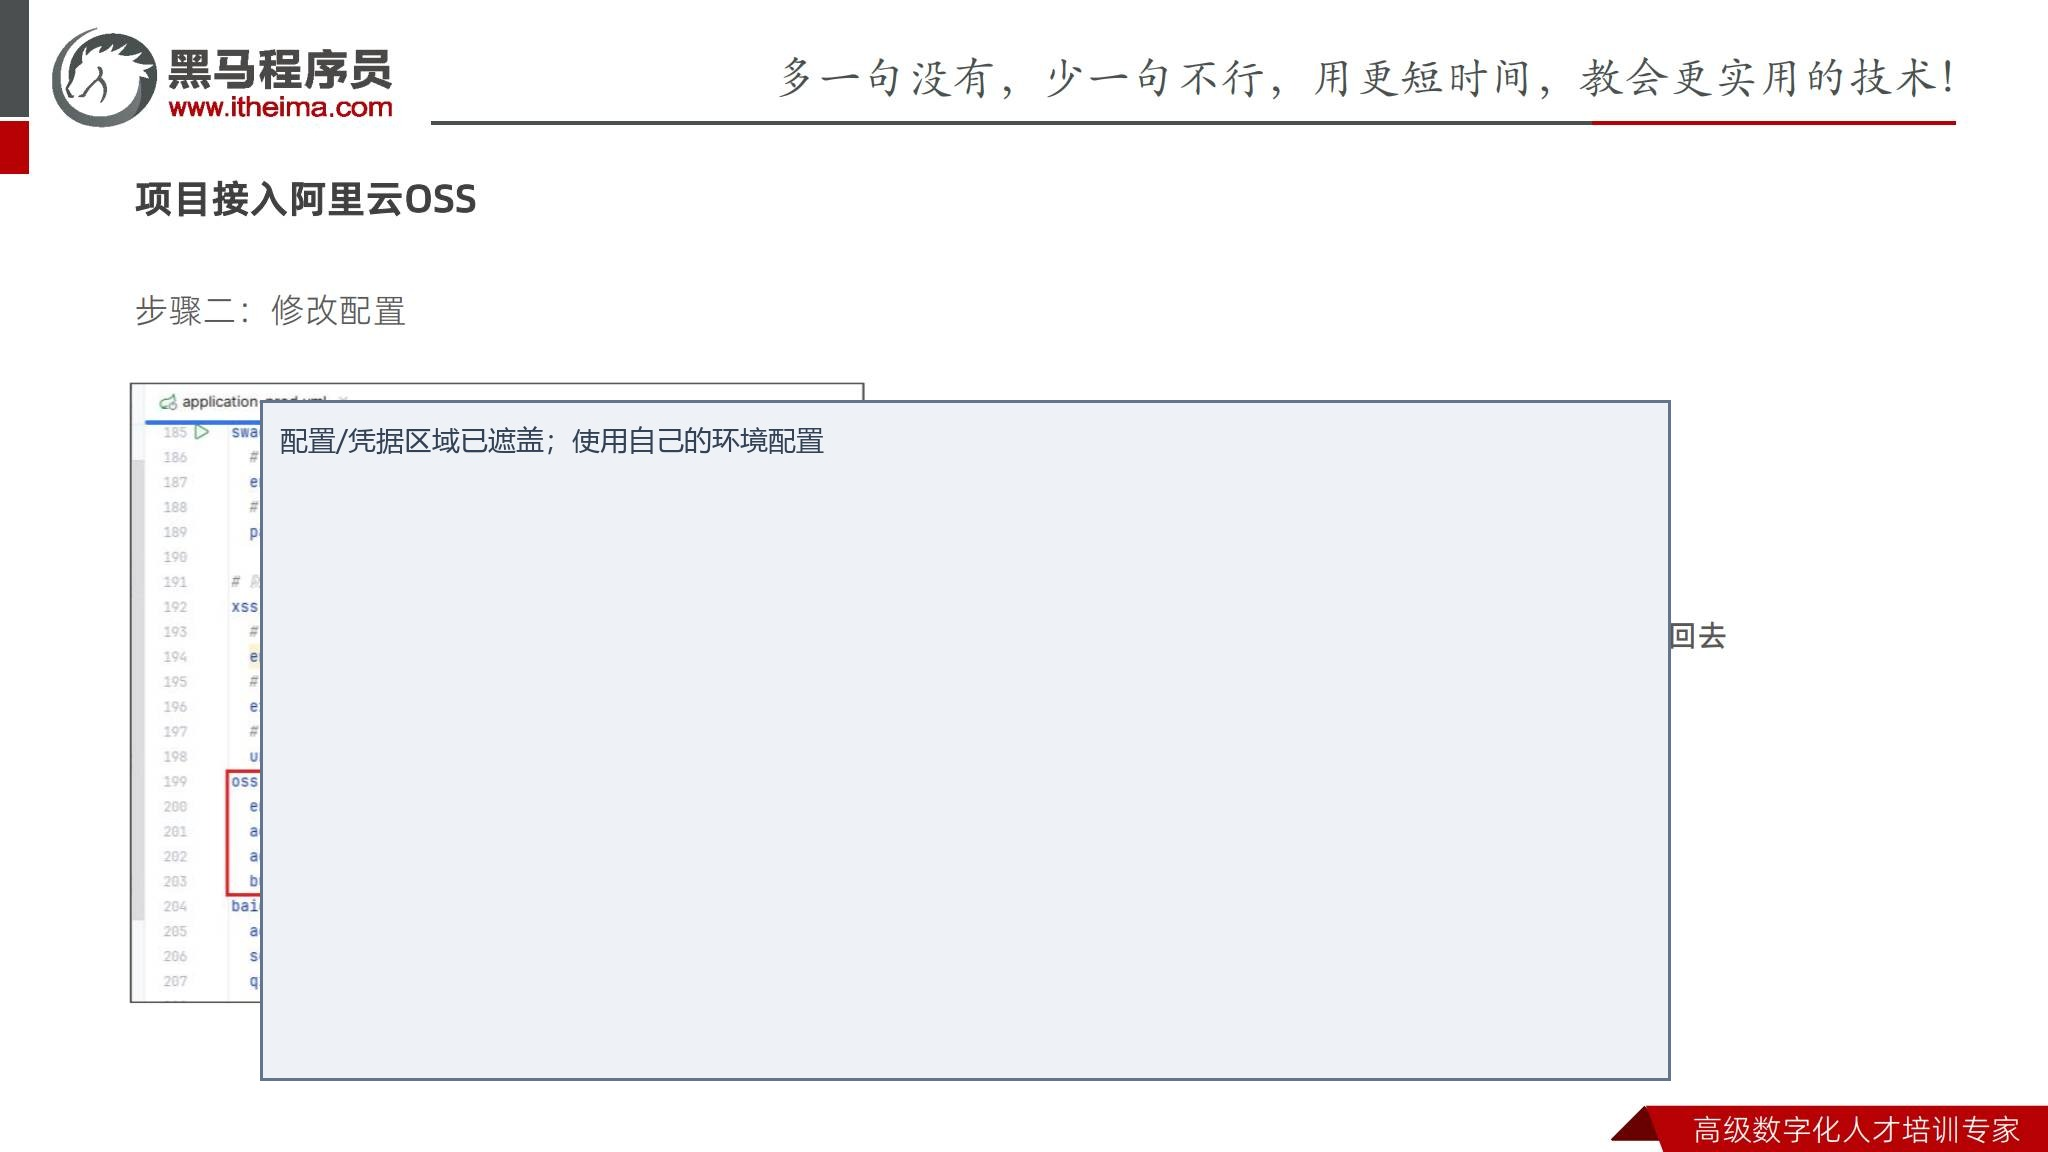

推荐把配置改为环境变量，示意如下：

```bash
export OSS_ACCESS_KEY_ID='从密钥管理服务注入'
export OSS_ACCESS_KEY_SECRET='从密钥管理服务注入'
export OSS_BUCKET='zzyl-prod-example'
export OSS_ENDPOINT='oss-cn-example.aliyuncs.com'
```

应用启动前确认配置已加载，上传一张非敏感测试图片，验证上传、下载/签名访问、删除和异常重试。检查 bucket 地域、endpoint、权限和跨域策略一致。生产配置变更后保留可回滚版本，不要直接覆盖唯一配置文件。

### 5.4 OSS 验收清单

- 应用只拥有目标 bucket 的最小权限。
- 私有对象通过有效期有限的签名 URL 访问。
- 文件大小、类型和对象 key 有服务端校验，避免任意路径和恶意内容。
- 备份和生命周期规则已配置，费用可追踪。
- 日志和审计打开，密钥轮换和吊销流程已记录。


## 六、百度千帆授权与项目接入

### 6.1 项目中的 AI 能力

**原课依据：第 47-55 页。** 养老项目使用百度千帆大模型分析用户体检报告。流程是注册百度智能云账号、完成实名认证、进入千帆 ModelBuilder 管理平台、开通模型服务并申请授权。

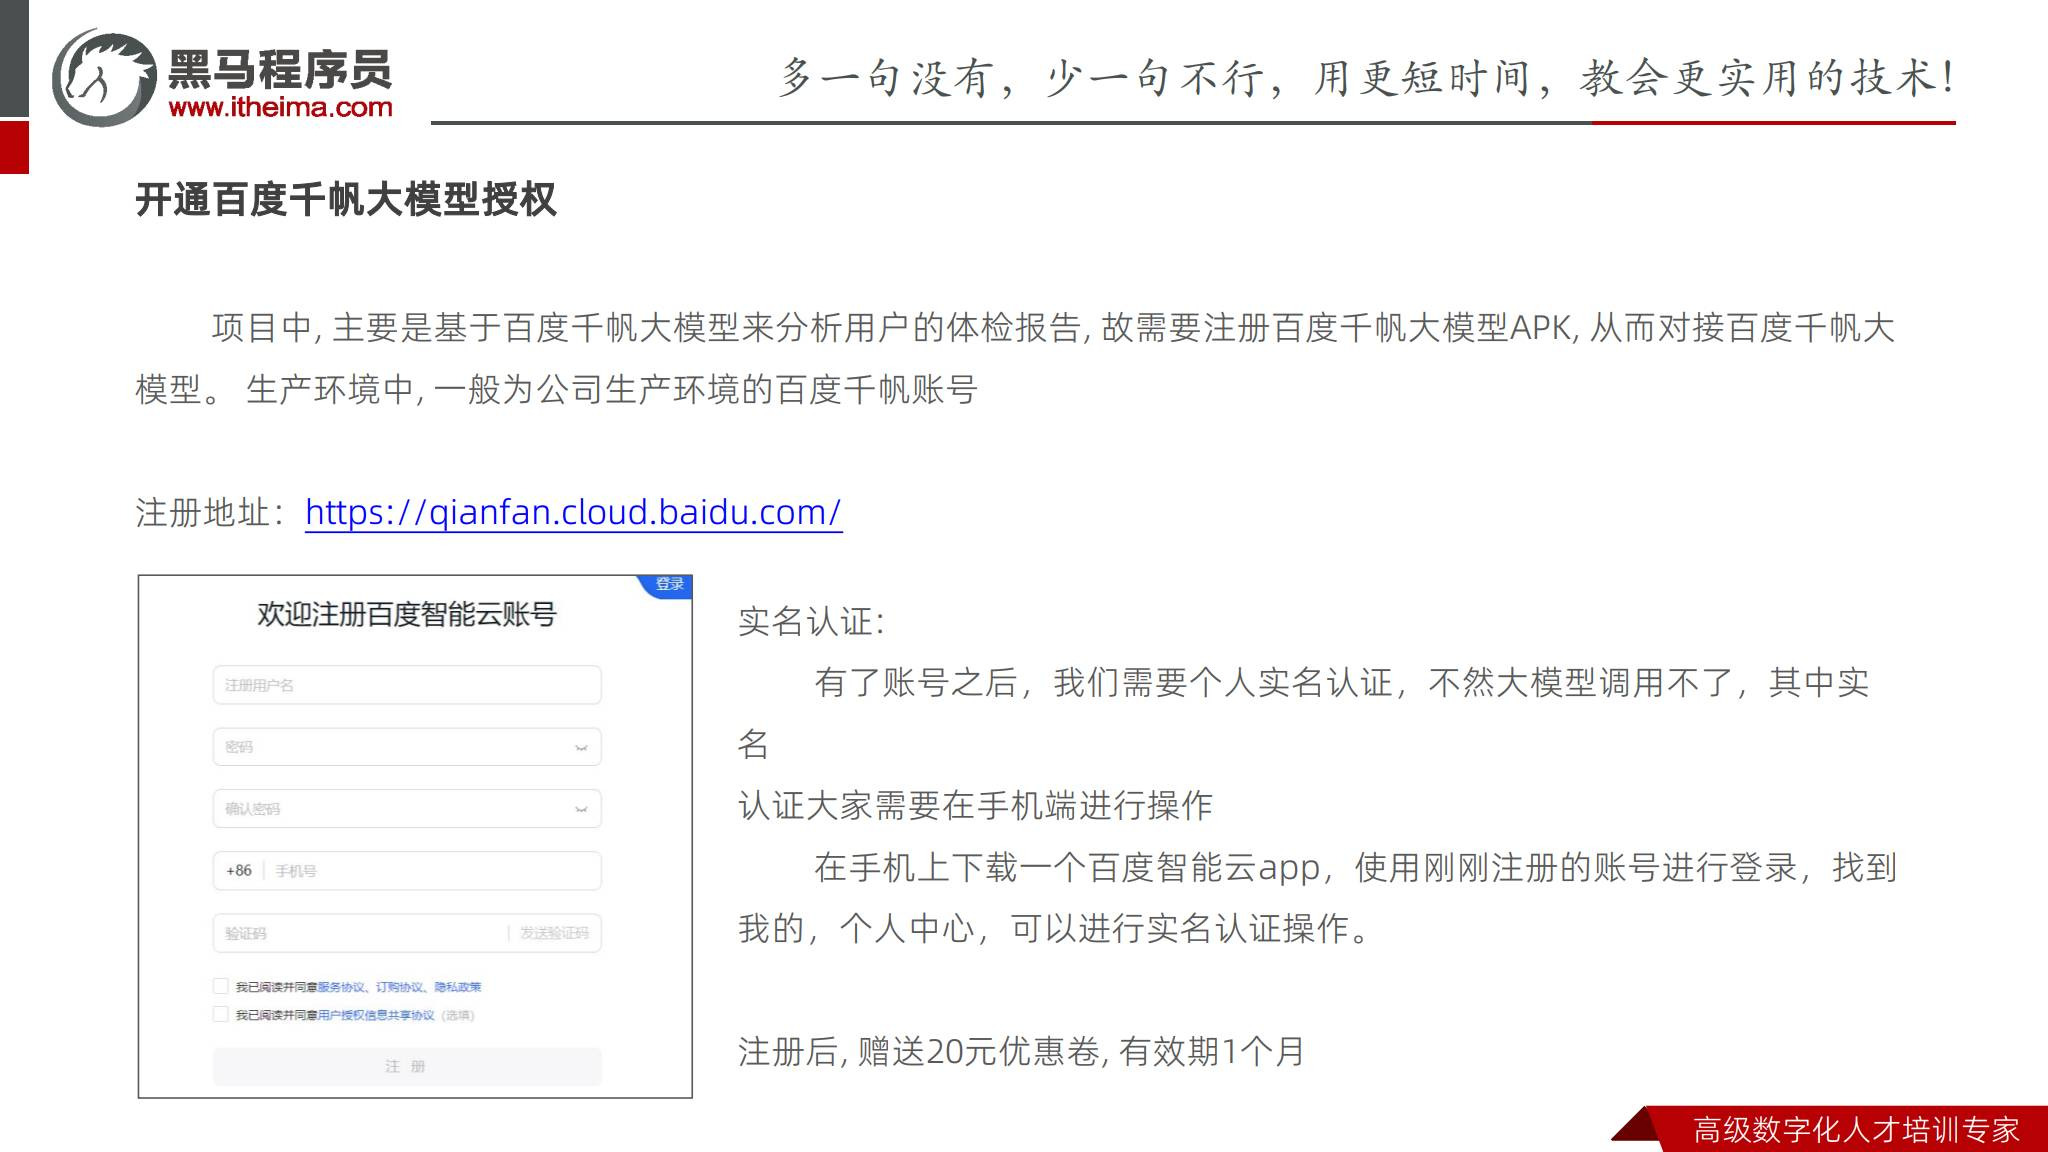

账号注册地址和控制台入口以百度官方页面为准。课件提到的优惠券、模型和价格具有时效性，实际使用前核对计费、配额、数据处理协议和组织账号归属。

### 6.2 凭据与模型服务

```text
应用配置需要：API 访问 ID、Secret/Token、模型或服务标识、区域/Endpoint。
这些值从密钥管理服务注入，不能硬编码到后端仓库或前端 dist。
```

最小权限、配额限制、调用超时、重试退避和错误脱敏都应在上线前配置。体检报告属于敏感健康信息，应确认用户授权、传输加密、保存期限和脱敏策略；不要把真实报告复制进学习目录。

### 6.3 接入测试

先在测试环境使用虚拟数据：

1. 检查服务凭据可用但权限只覆盖目标模型。
2. 发送最小测试请求，验证超时、限流、鉴权失败和服务不可用时的错误处理。
3. 记录 request id、耗时和计费信息，不记录完整报告和 Secret。
4. 在生产配置中只替换经过审批的凭据，不把测试 key 与生产 key 混用。

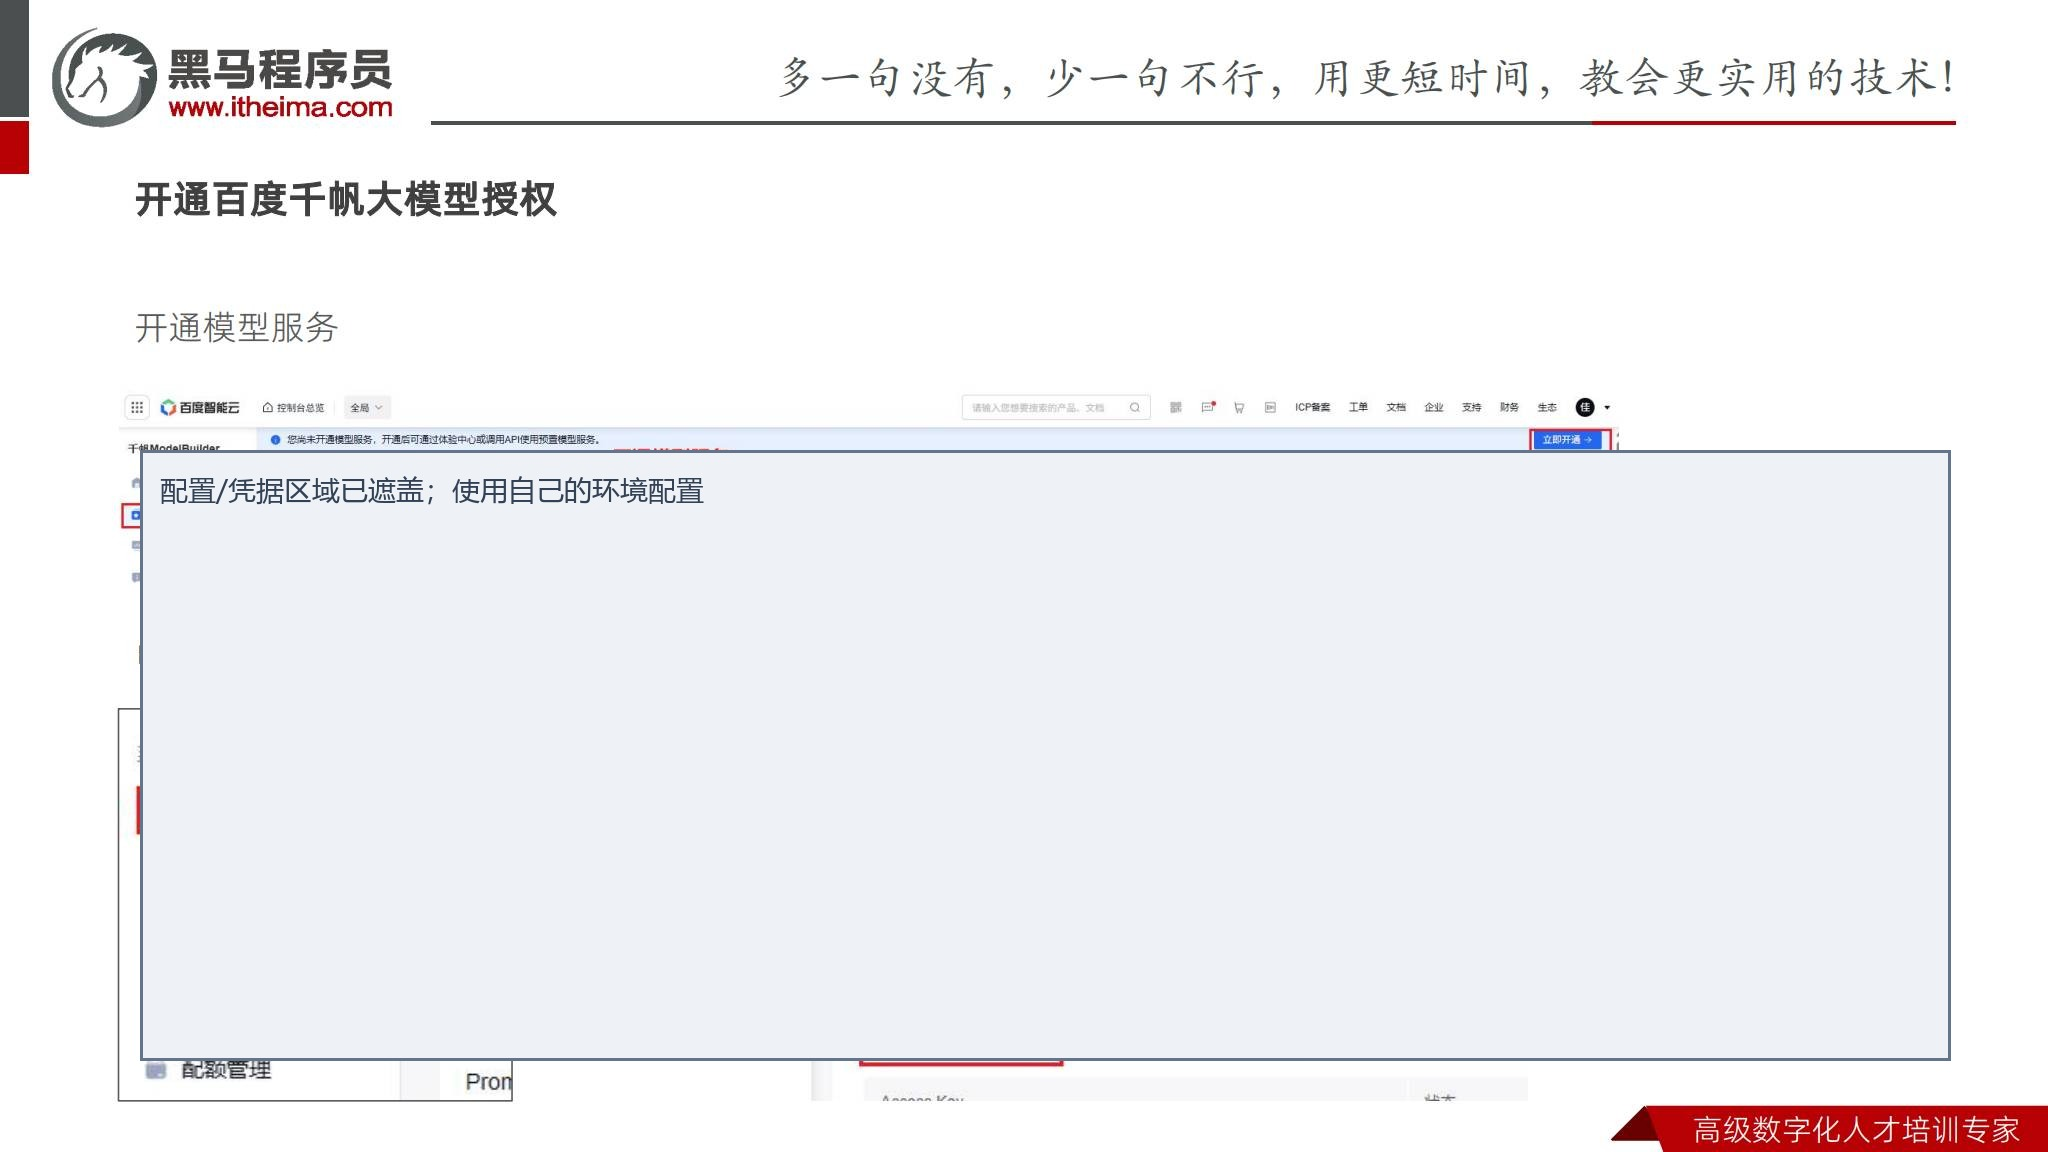

### 6.4 项目配置接入

**原课依据：第 52-55 页。** 课件仍采用“拖出生产配置文件，修改授权 ID/Secret，再放回”的方式。更稳妥的做法是由部署脚本或密钥管理系统渲染模板，并在发布前检查文件权限：

```bash
umask 077
install -m 0600 /secure/runtime/zzyl.env /opt/zzyl/backend/zzyl.env
systemctl restart zzyl-backend
systemctl status zzyl-backend --no-pager
```

**整理补充：** 如果必须手工修改配置，先备份、校验格式、限制文件权限、记录变更单，并在应用日志中确认鉴权成功。禁止把真实密钥粘贴到 Notebook。


## 七、Java 后端服务部署

### 7.1 JDK 与 Jar

**原课依据：第 56-65 页。** Java 后端需要 JDK/JRE 运行环境。课程以 node2 为后端节点，创建 `/opt/zzyl/backend`，上传 `zzyl-admin.jar`，再用 `java -jar` 启动。

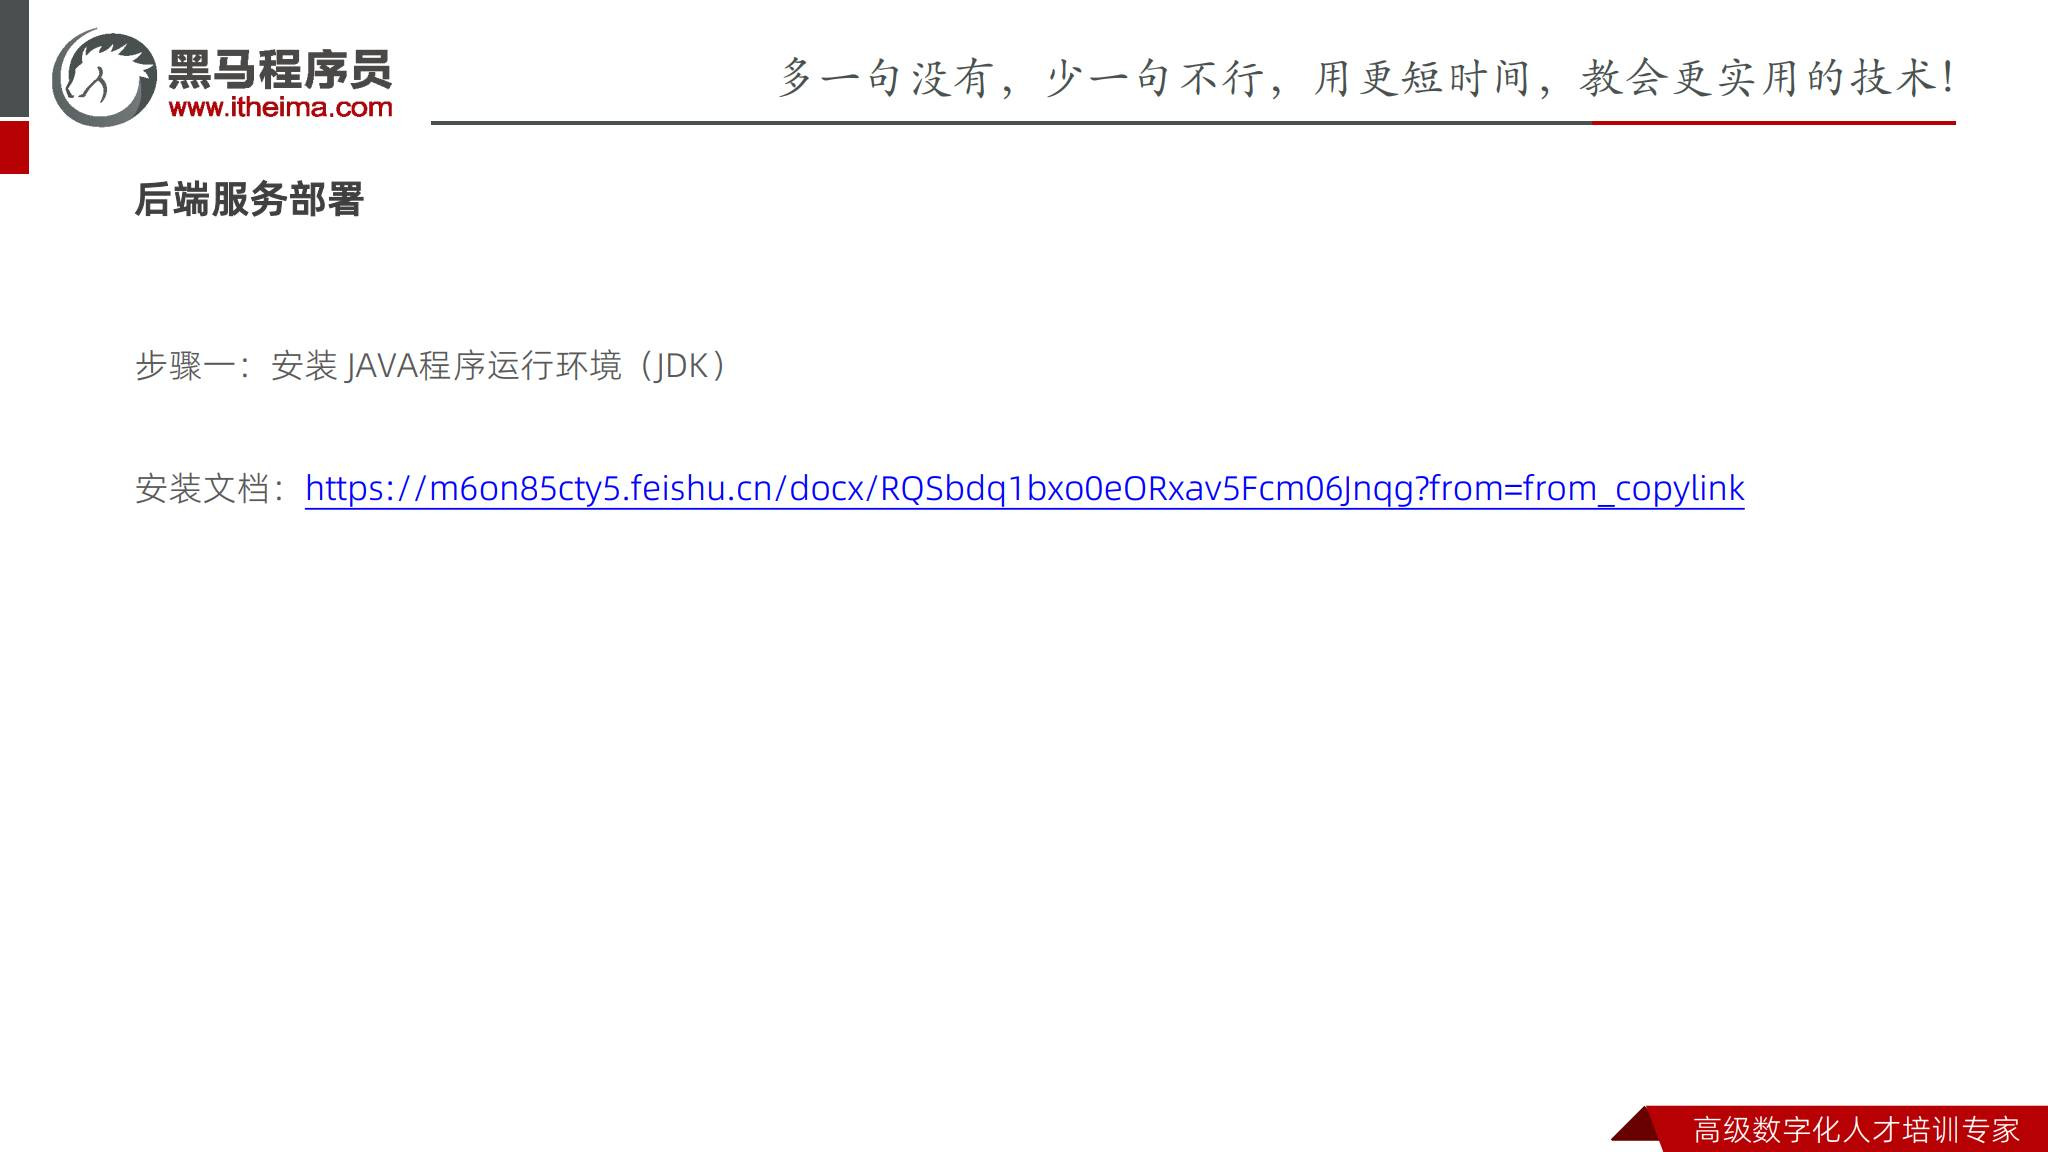

安装 JDK 时根据 Jar 的编译版本选择相容的 JDK，并核对来源和校验值：

```bash
java -version
mkdir -p /opt/zzyl/backend
sha256sum /opt/zzyl/backend/zzyl-admin.jar
```

### 7.2 前台启动与 screen

```bash
cd /opt/zzyl/backend
java -jar zzyl-admin.jar
```

前台启动会占用当前终端，断开 SSH 也可能使进程结束。课件使用 screen 建立持久会话：

```bash
sudo dnf install -y epel-release
sudo dnf install -y screen
screen -S zzyl-backend
cd /opt/zzyl/backend
java -jar zzyl-admin.jar
# Ctrl+A，再按 D：分离会话，进程继续运行
screen -ls
screen -r zzyl-backend
# 在会话中 Ctrl+D：结束前台进程并关闭会话
```

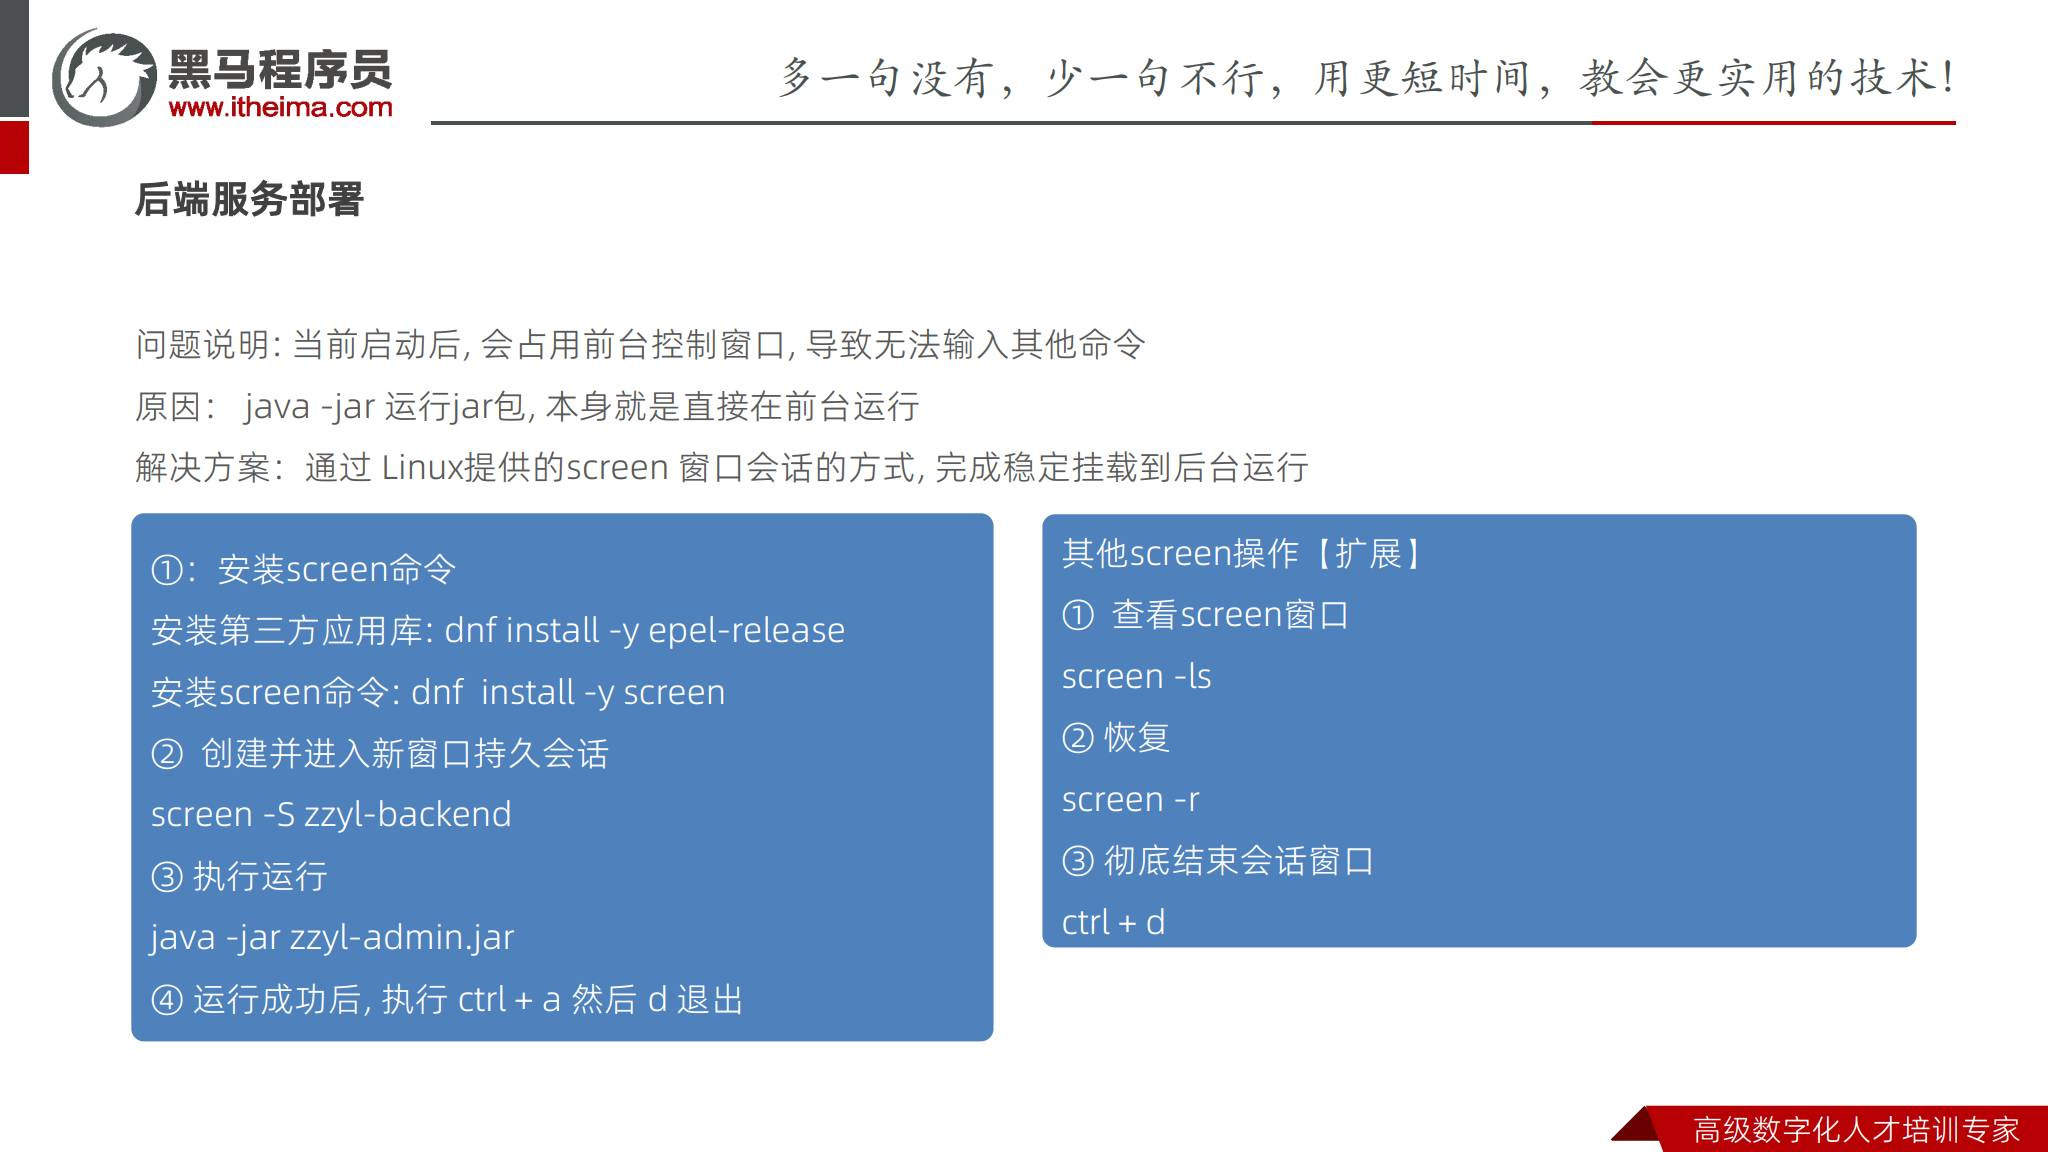

**整理补充：** screen 适合课程练习和临时排查，生产服务更推荐 systemd、容器编排或进程管理器，具备自动重启、日志、资源限制和统一状态管理。不要同时用 screen 和 systemd 启动两份实例。

### 7.3 后端验收

```bash
curl -fsS http://127.0.0.1:8080/actuator/health || true
ss -lntp | grep ':8080'
tail -n 100 /var/log/zzyl/backend.log
```

实际健康检查路径由应用提供；不要因为端口监听就认为数据库、Redis、OSS 和千帆都已正常。检查启动日志中的配置加载、数据库连接、缓存连接和端口冲突。


## 八、Nginx 与前端服务

### 8.1 Nginx 的两个职责

**原课依据：第 66-72 页。** Nginx 是 Web 服务器和反向代理：一方面返回前端静态文件，另一方面把 API 请求转发给 node2。它还可承担 TLS、缓存、限流和负载均衡等职责。

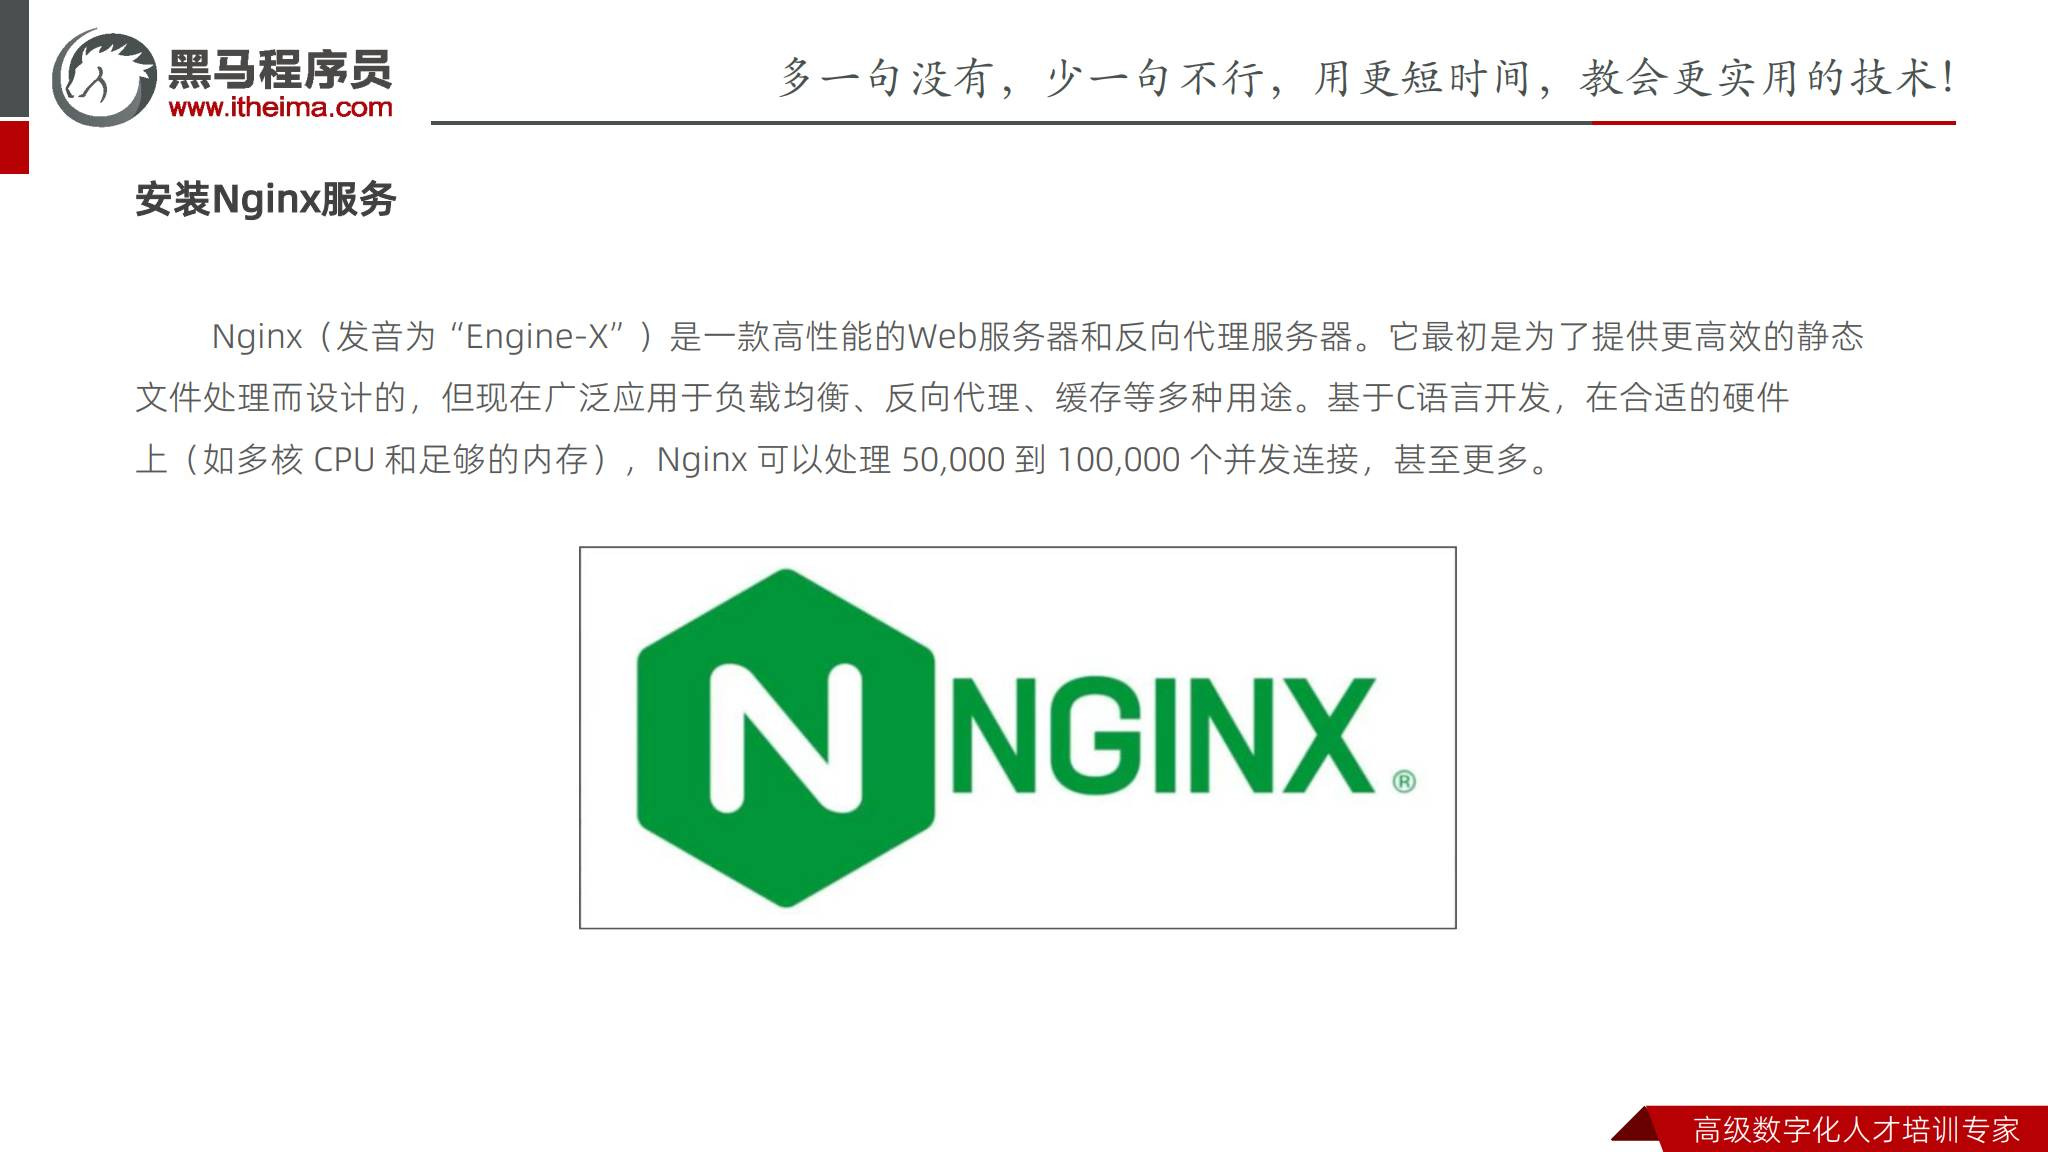

### 8.2 上传 dist 并配置静态页面

**原课依据：第 73-85 页。** 将构建后的 `dist` 上传到 node3 的 `/var/www/dist`：

```bash
sudo mkdir -p /var/www/dist
# 由受控传输工具上传 dist 内容，并核对文件清单
sudo find /var/www/dist -maxdepth 2 -type f | head
```

在 HTTP 或 server 配置中添加 CORS、请求缓冲和静态页面配置。下面是课件配置的结构化示例，域名、路径和后端私网地址必须按实际环境替换：

```nginx
http {
    # 仅在确有跨域需求时配置，并尽量把 * 收窄为明确的前端域名
    add_header Access-Control-Allow-Origin "https://app.example.com" always;
    add_header Access-Control-Allow-Methods "GET, POST, OPTIONS, PUT, DELETE" always;
    add_header Access-Control-Allow-Headers "Origin, X-Requested-With, Content-Type, Accept, Authorization" always;

    server {
        listen 80;
        server_name app.example.com;
        client_max_body_size 60m;
        client_body_buffer_size 512k;
        client_header_buffer_size 2k;

        location / {
            root /var/www/dist;
            index index.html;
            try_files $uri $uri/ /index.html;
        }

        location /prod-api/ {
            proxy_pass http://192.168.88.102:8080/zzyl-admin/;
            proxy_set_header Host $host;
            proxy_set_header X-Real-IP $remote_addr;
            proxy_set_header X-Forwarded-For $proxy_add_x_forwarded_for;
            proxy_set_header X-Forwarded-Proto $scheme;
        }
    }
}
```

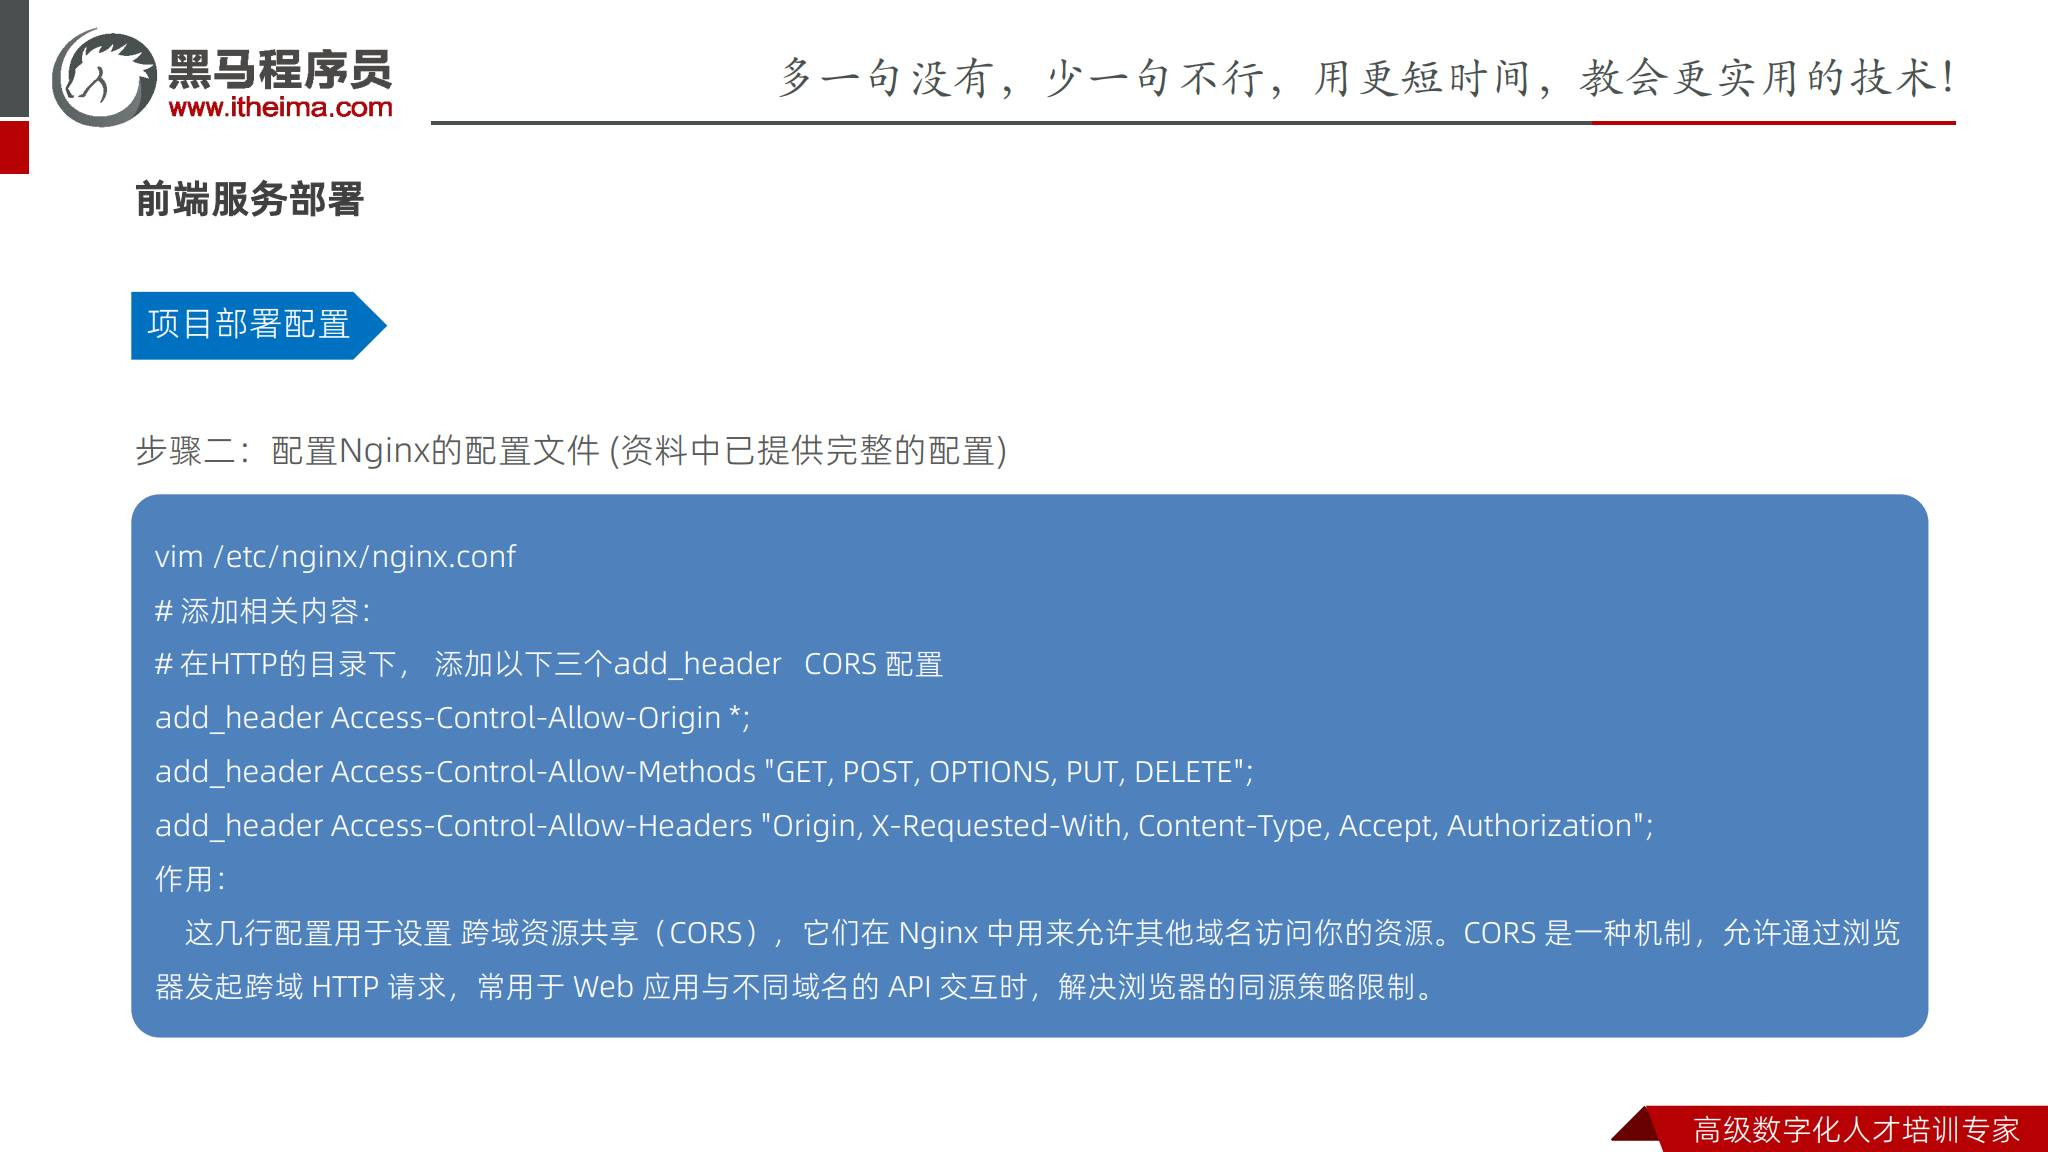

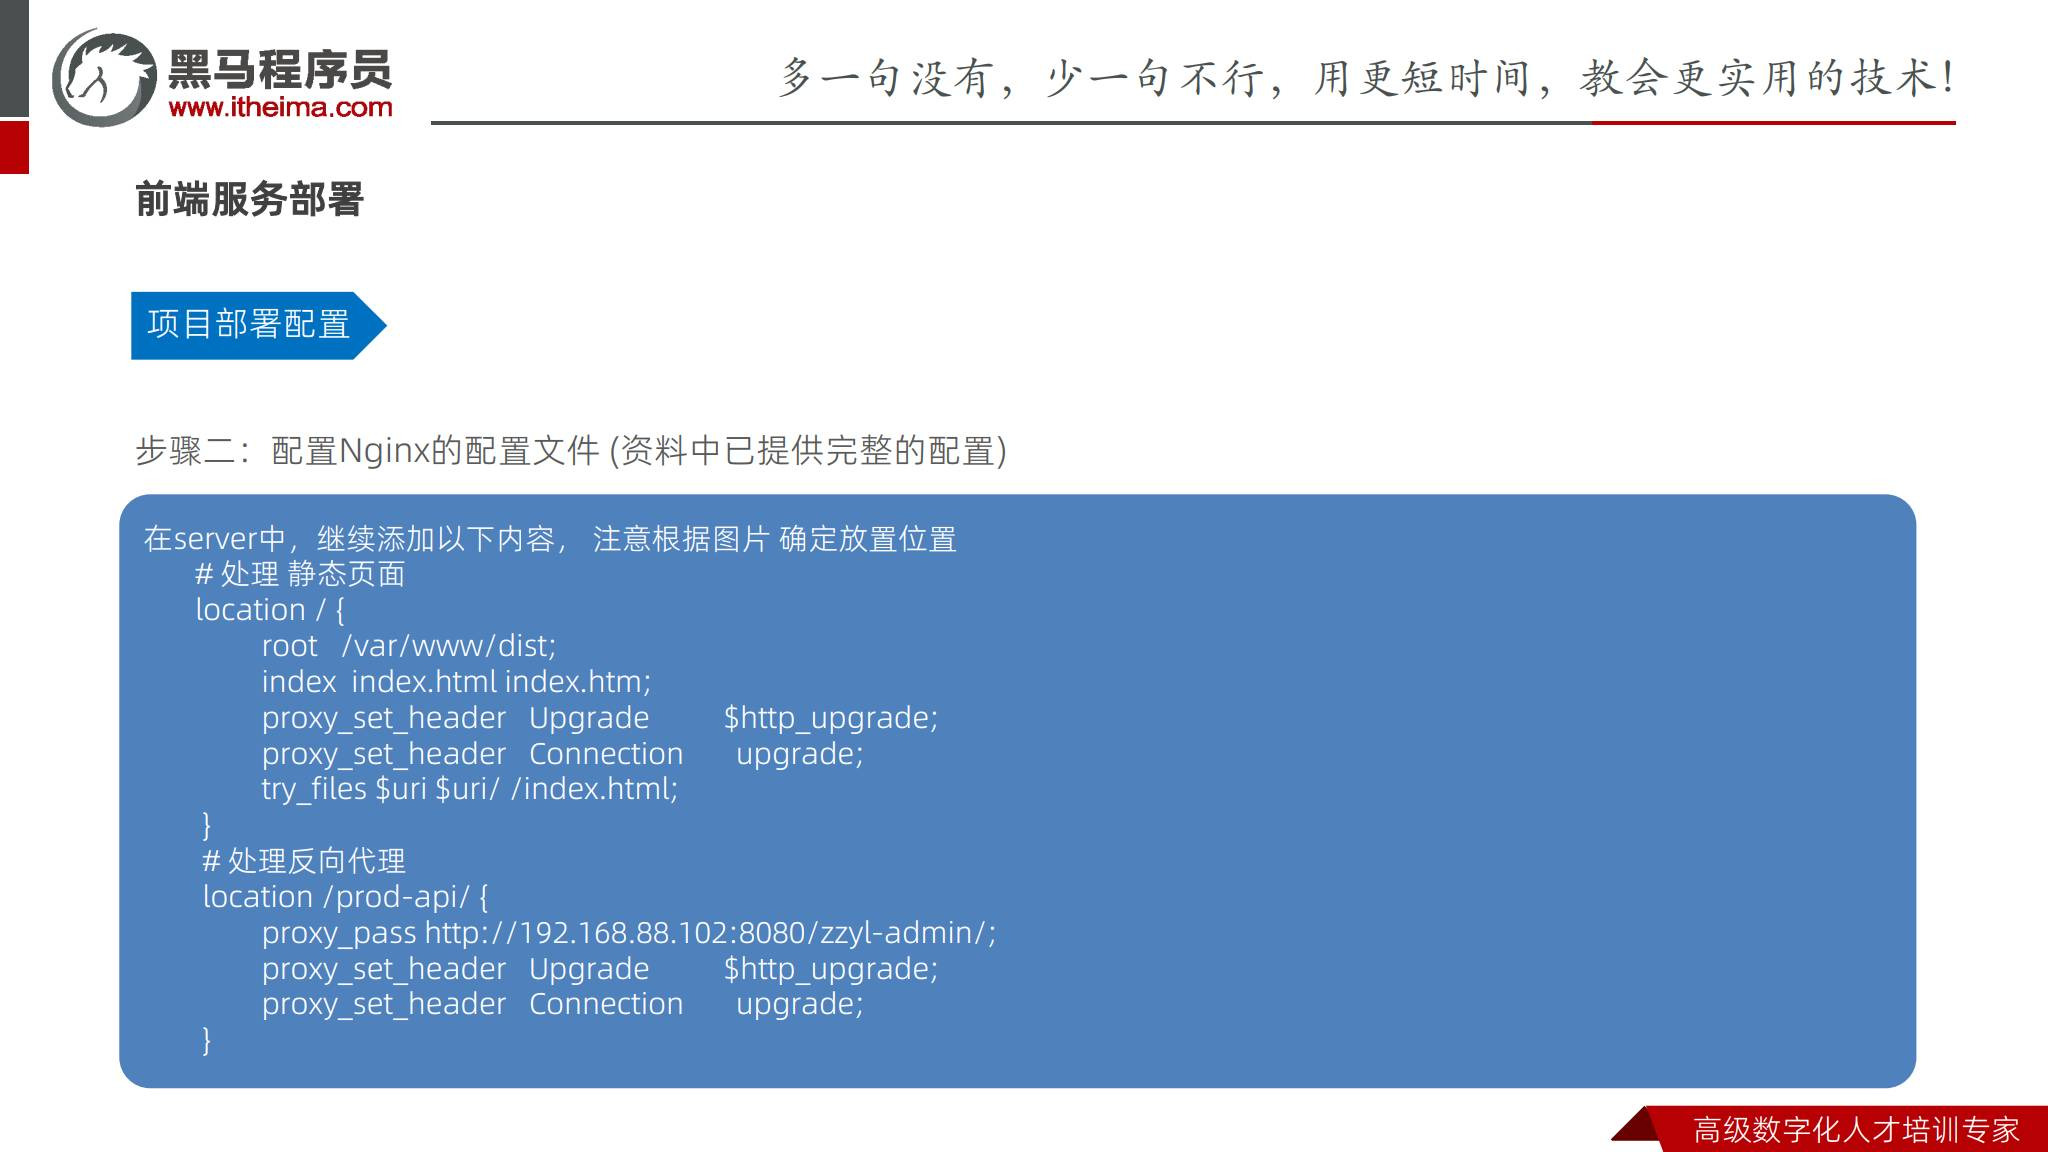

**整理补充：** 课件使用 `Access-Control-Allow-Origin *` 的教学示例，但带凭据的生产请求不能和 `*` 混用，来源应收窄。`proxy_pass` 末尾斜杠会影响 URI 拼接，必须用实际后端路由测试。

### 8.3 检查、重载和访问

```bash
sudo nginx -t
sudo systemctl reload nginx
sudo systemctl status nginx --no-pager
curl -I http://127.0.0.1/
curl -i http://127.0.0.1/prod-api/health
```

配置错误时不要直接重启覆盖现有服务；先 `nginx -t`，确认通过后再 reload。浏览器访问 node3 公网 IP 或正式域名，检查静态页面、刷新深层路由、API、上传大小和跨域响应。

### 8.4 前端上线验收

- `index.html`、JS、CSS 和资源路径可访问。
- Vue/React 等前端刷新深层路由不会出现 404。
- `/prod-api/` 确实转发到 node2，响应路径没有重复或缺失前缀。
- 浏览器 Network 面板中没有混合内容、CORS、404、502 和超时错误。
- 只开放 80/443；后端 8080、数据库 3306、Redis 6379 走私网。


## 九、上线顺序与故障排查

### 9.1 推荐发布顺序

1. 备份数据库、配置和当前 dist，记录版本号与哈希。
2. 先确认 node1 的 MySQL 和 Redis 健康，再发布 node2 后端。
3. 在 node2 本机调用健康接口，确认后端依赖可用。
4. 上传 node3 的新 dist 和 Nginx 配置，运行 `nginx -t` 后 reload。
5. 从浏览器和小程序分别做核心业务流程测试。
6. 观察 Nginx、后端、数据库、Redis、OSS 和千帆调用日志。
7. 设置回滚点和停止发布条件，出现错误按版本回退。

### 9.2 按请求路径排查

| 现象 | 检查顺序 |
| --- | --- |
| 页面打不开 | DNS/公网 IP、安全组、Nginx 状态、80/443 监听 |
| 页面 404 | dist 路径、`root`、`try_files`、大小写 |
| API 404 | `/prod-api/` 前缀、`proxy_pass` 斜杠、后端实际 context-path |
| API 502 | node2 进程、8080 监听、私网路由、安全组、Nginx error log |
| 登录失败 | 后端日志、数据库连接、Redis、时间同步和 token 配置 |
| 图片不显示 | OSS endpoint、bucket 权限、签名 URL、浏览器跨域 |
| AI 分析失败 | 千帆凭据、配额、模型标识、超时、敏感内容策略 |

```bash
sudo journalctl -u nginx -n 100 --no-pager
sudo journalctl -u zzyl-backend -n 100 --no-pager
curl -v http://127.0.0.1/prod-api/health
```

**整理补充：** 日志排查应带时间范围、request id 和脱敏后的用户信息。不要把整段生产日志、体检报告、token 或数据库导出文件复制到学习目录。


## 十、ChatGLM-6B 私有化部署准备

### 10.1 服务器规格

**原课依据：第 86-97 页。** 后半部分是智能客服私有化部署，不是前三台业务节点的必然组成。课件给出的 ChatGLM-6B 练习建议：Linux；GPU 显存最低 4 GB、建议 8 GB 以上；内存至少 8 GB；CPU 至少 4 核；磁盘建议 40 GB 以上。

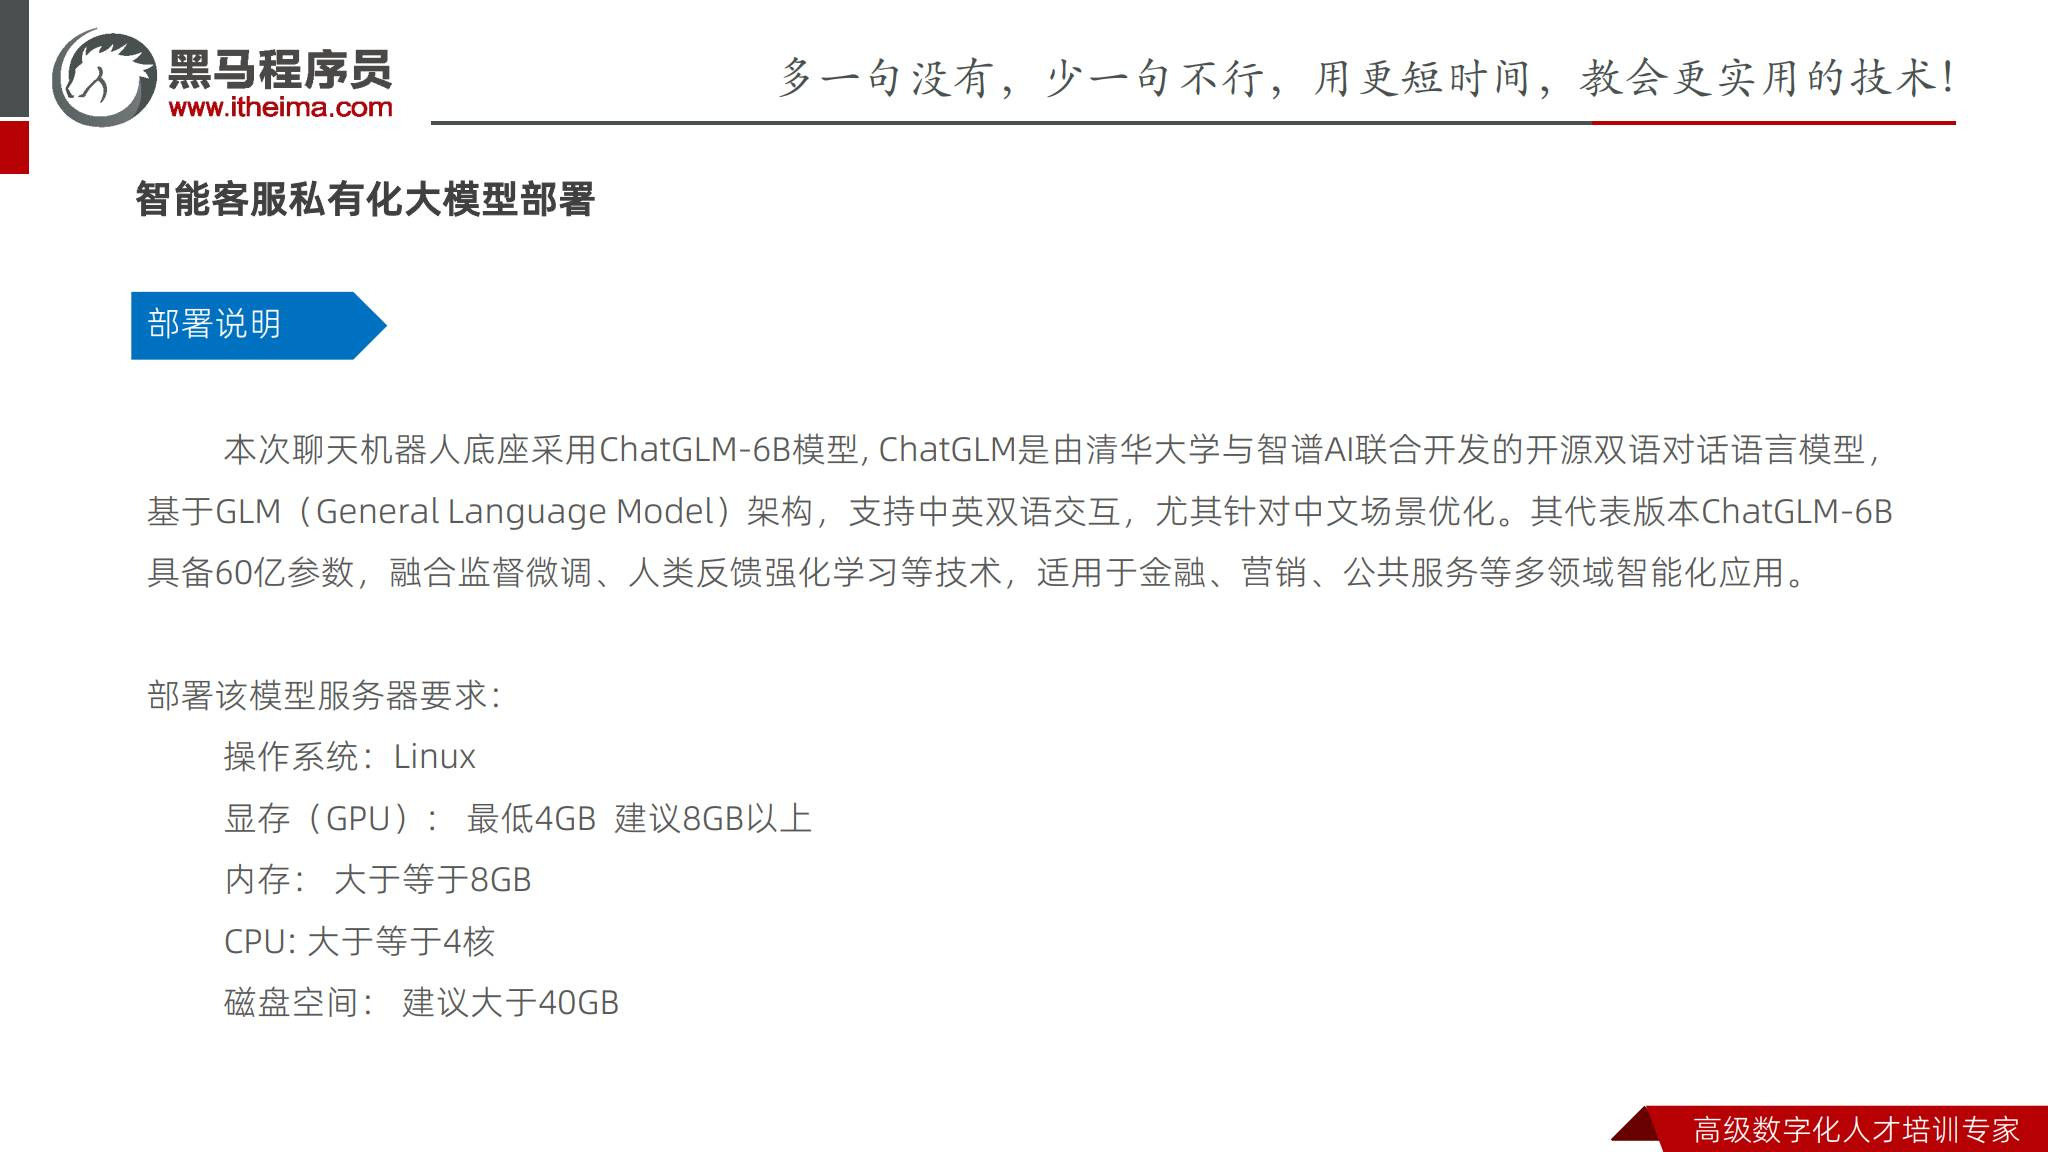

申请 GPU ECS 时检查实例、镜像、系统盘、安全组和远程连接。系统盘建议 60 GB 以上，实际还要为模型、缓存、日志和临时文件留出空间。GPU 规格、驱动、CUDA 和模型量化版本必须相互兼容。

### 10.2 NVIDIA 驱动

**原课依据：第 98-103 页。** 先确认显卡和驱动状态：

```bash
lspci | grep -i nvidia
nvidia-smi
```

课件以 CUDA 12.6.3 安装包为例：

```bash
wget https://developer.download.nvidia.com/compute/cuda/12.6.3/local_installers/cuda_12.6.3_560.35.05_linux.run
sh cuda_12.6.3_560.35.05_linux.run
```

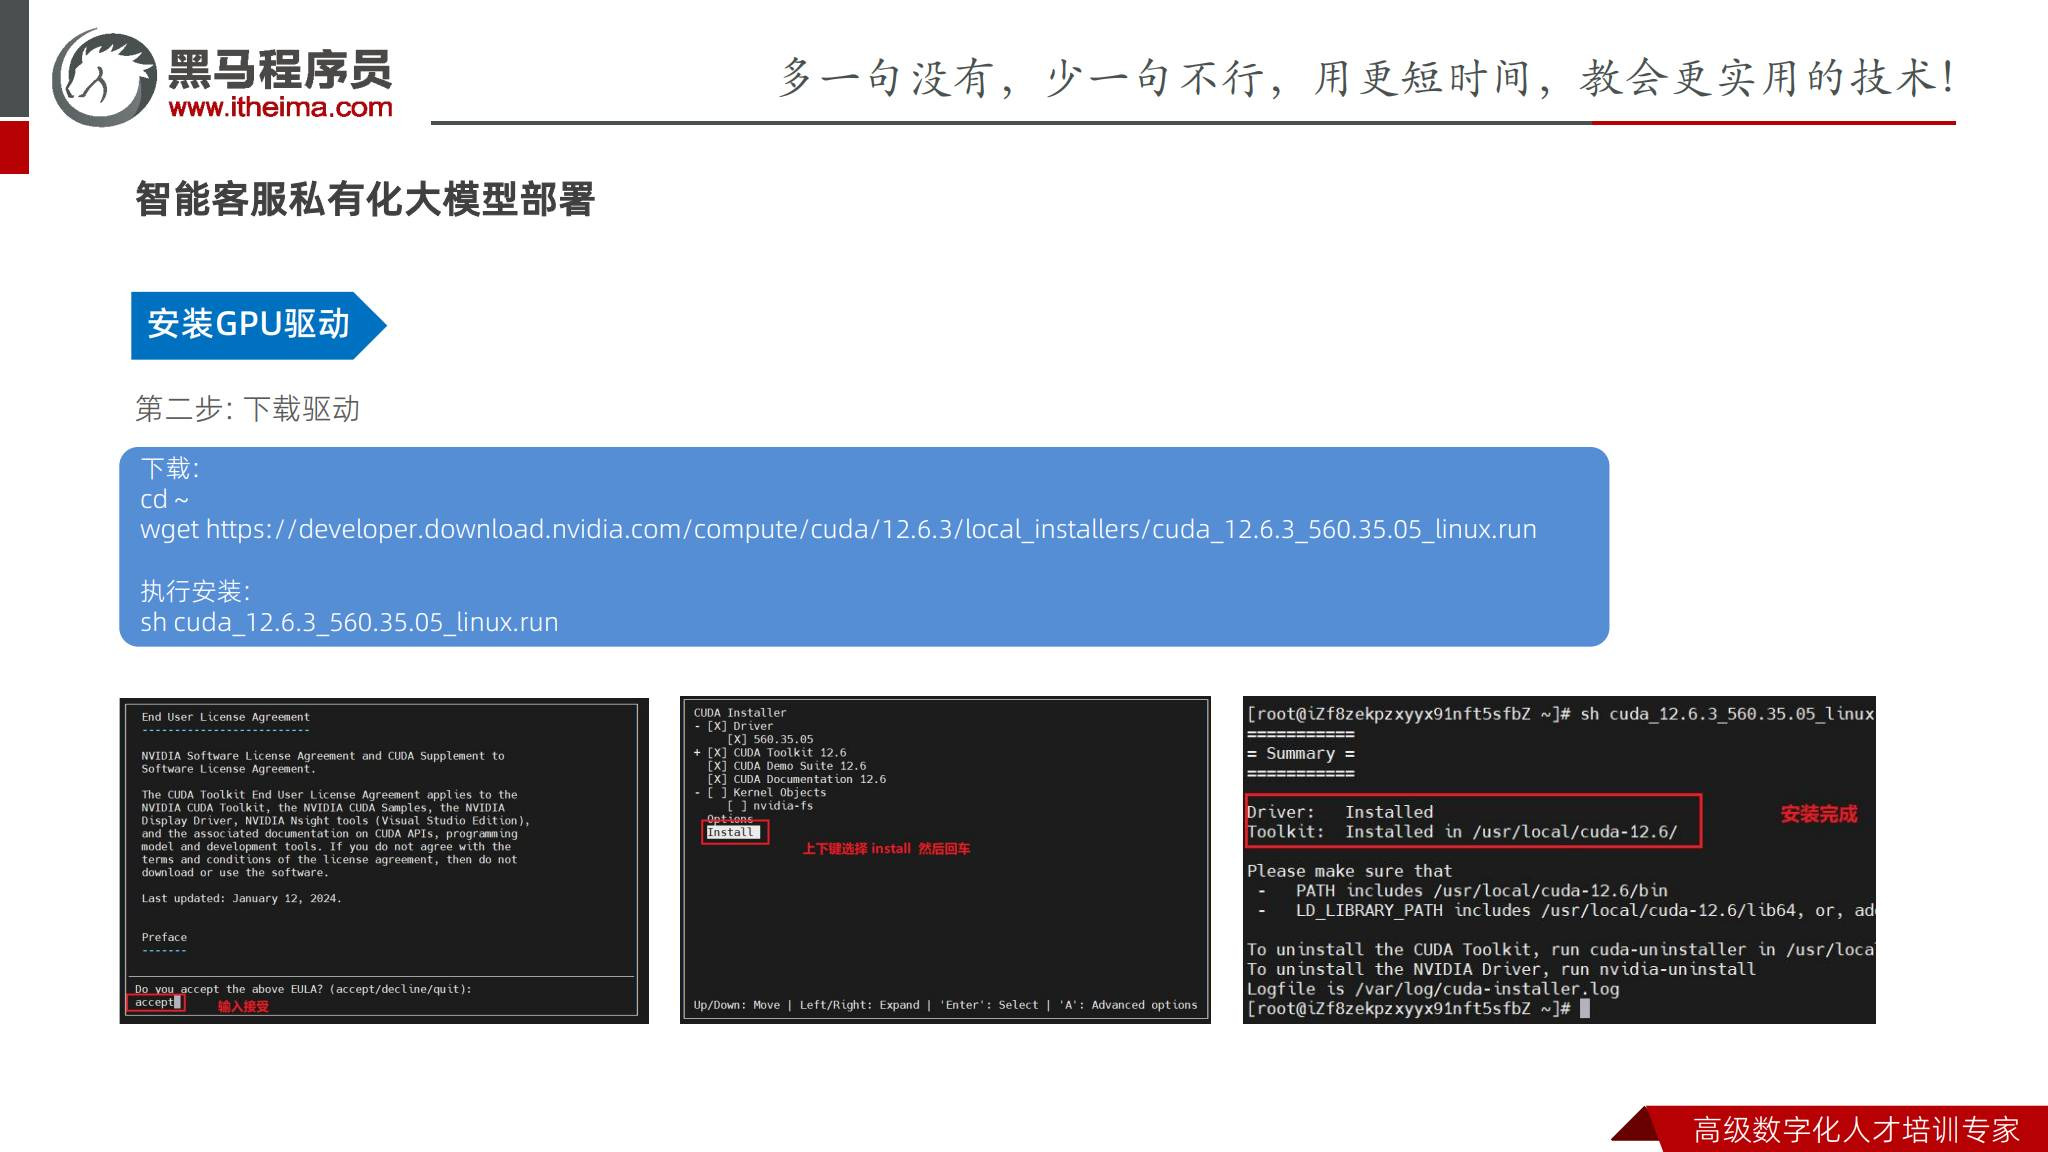

**整理补充：** 不要盲目复制旧版本 URL。根据 GPU、发行版内核和 CUDA/PyTorch 支持矩阵，从 NVIDIA 官方页面选择驱动；安装前建立快照或回滚方案。驱动安装需要管理员权限，安装包应校验来源和哈希。

环境变量示例：

```bash
echo 'export PATH=/usr/local/cuda/bin:$PATH' >> ~/.bashrc
echo 'export LD_LIBRARY_PATH=/usr/local/cuda/lib64:${LD_LIBRARY_PATH:-}' >> ~/.bashrc
source ~/.bashrc
nvidia-smi
```

不要在系统级配置中重复追加同一变量；验证 `nvcc --version`、`nvidia-smi` 和框架检测结果一致。

### 10.3 Anaconda 基础环境

**原课依据：第 104-113 页。** 课程采用 Anaconda 管理 Python 与隔离环境：

```bash
wget https://repo.anaconda.com/archive/Anaconda3-2024.10-1-Linux-x86_64.sh
sha256sum Anaconda3-2024.10-1-Linux-x86_64.sh
bash Anaconda3-2024.10-1-Linux-x86_64.sh
```

安装过程中按提示阅读许可、确认安装路径，并只初始化需要的 shell。若没有自动初始化，可检查安装器生成的 `conda init` 内容，而不是直接复制带有固定 `/root` 的配置到所有用户。重新连接或 `source ~/.bashrc` 后验证：

```bash
conda --version
python --version
```

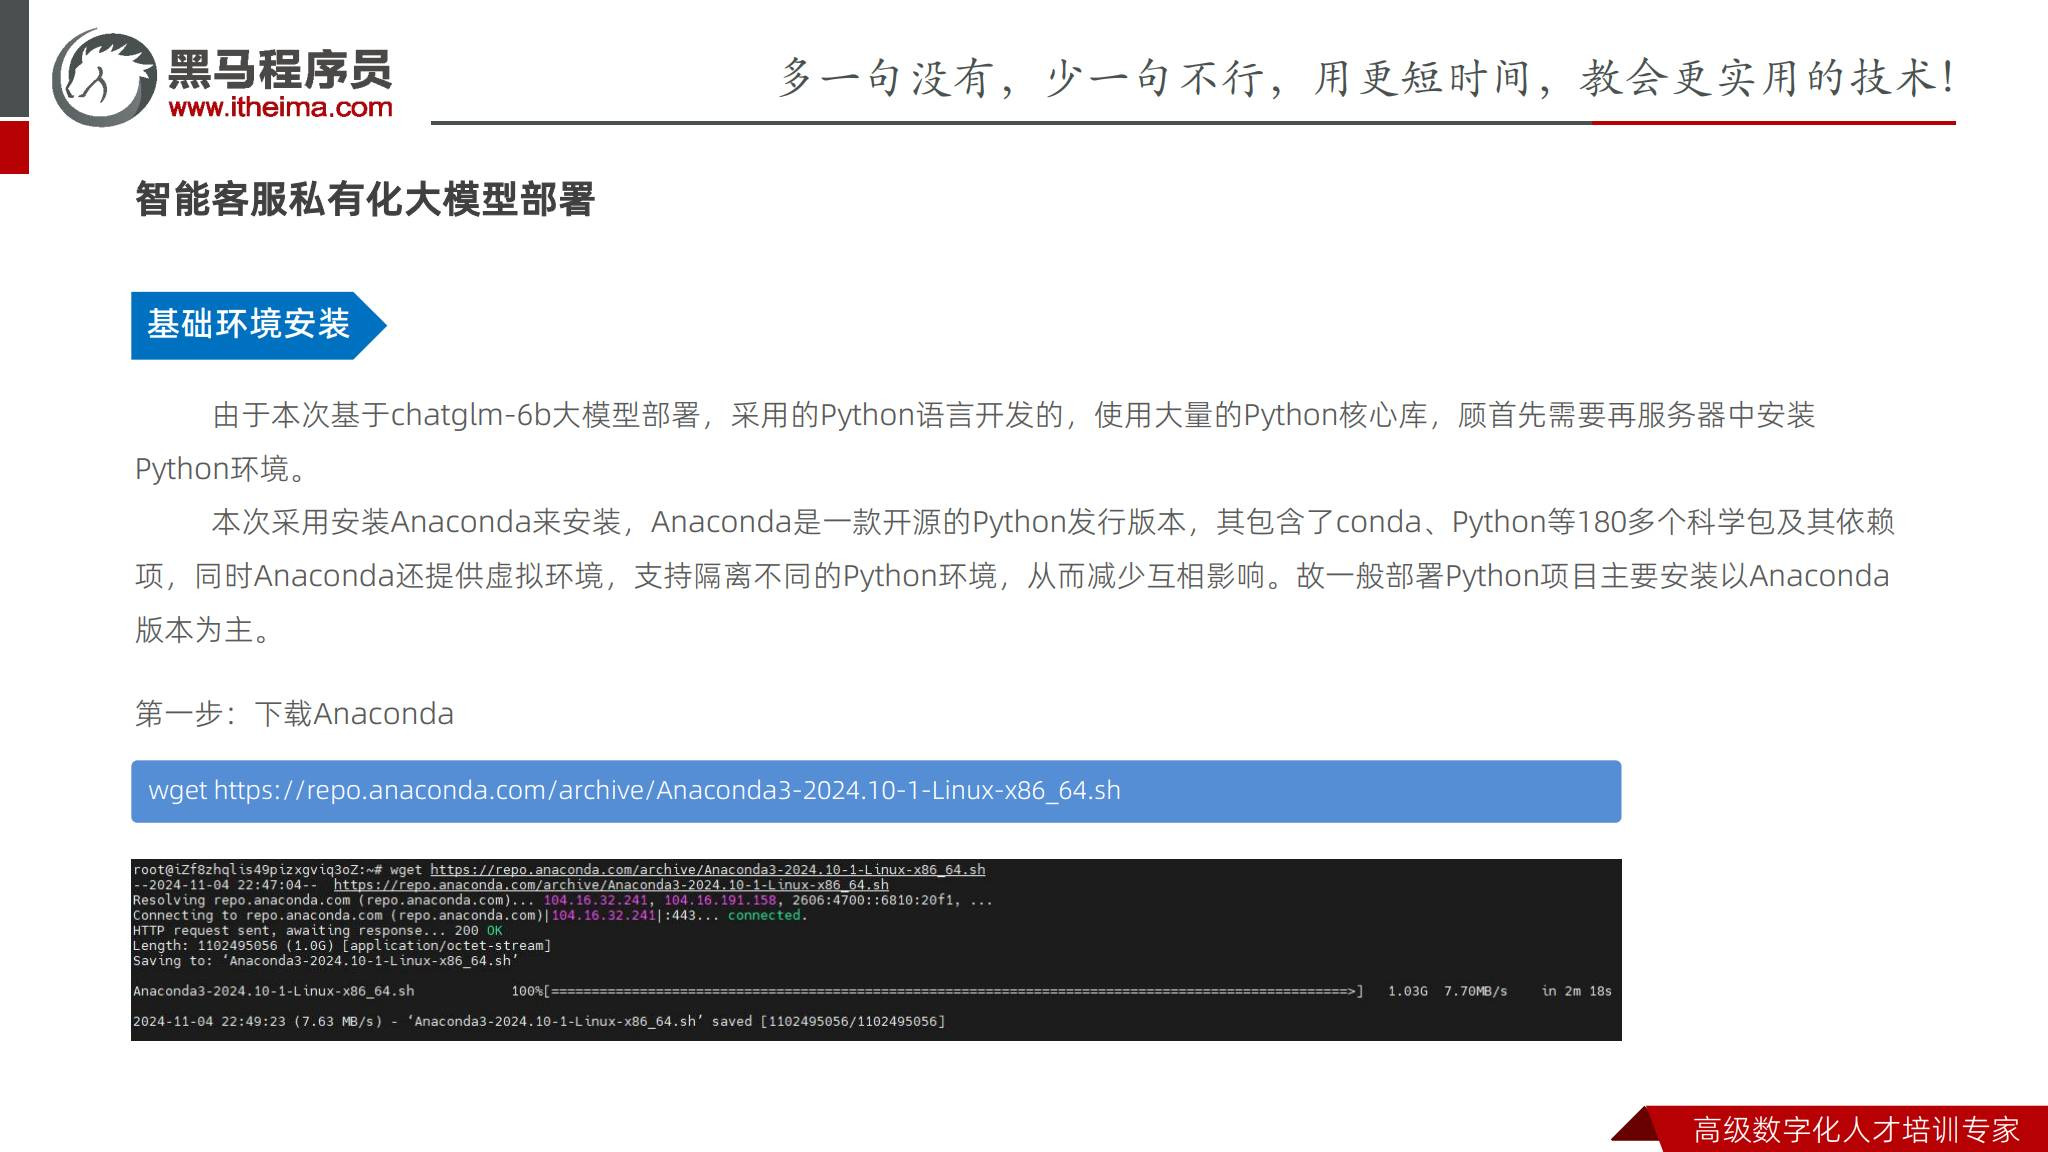

### 10.4 创建 ChatGLM 虚拟环境

```bash
conda create --name chatglm python=3.10
conda activate chatglm
python --version
```

每个项目使用独立环境；记录 Python、CUDA、PyTorch、transformers 等版本，以便复现。`conda deactivate` 可离开环境，但后续模型命令应在 `chatglm` 环境中执行。


## 十一、ChatGLM-6B 模型与代码

### 11.1 下载模型

**原课依据：第 114-118 页。** 课程把模型放到 `/export/data/glm`，使用 Hugging Face 镜像下载量化模型：

```bash
mkdir -p /export/data/glm
cd /export/data/glm
pip install -U huggingface_hub
export HF_ENDPOINT=https://hf-mirror.com
huggingface-cli download --resume-download THUDM/chatglm-6b-int4 \
  --local-dir THUDM/chatglm-6b-int4
```

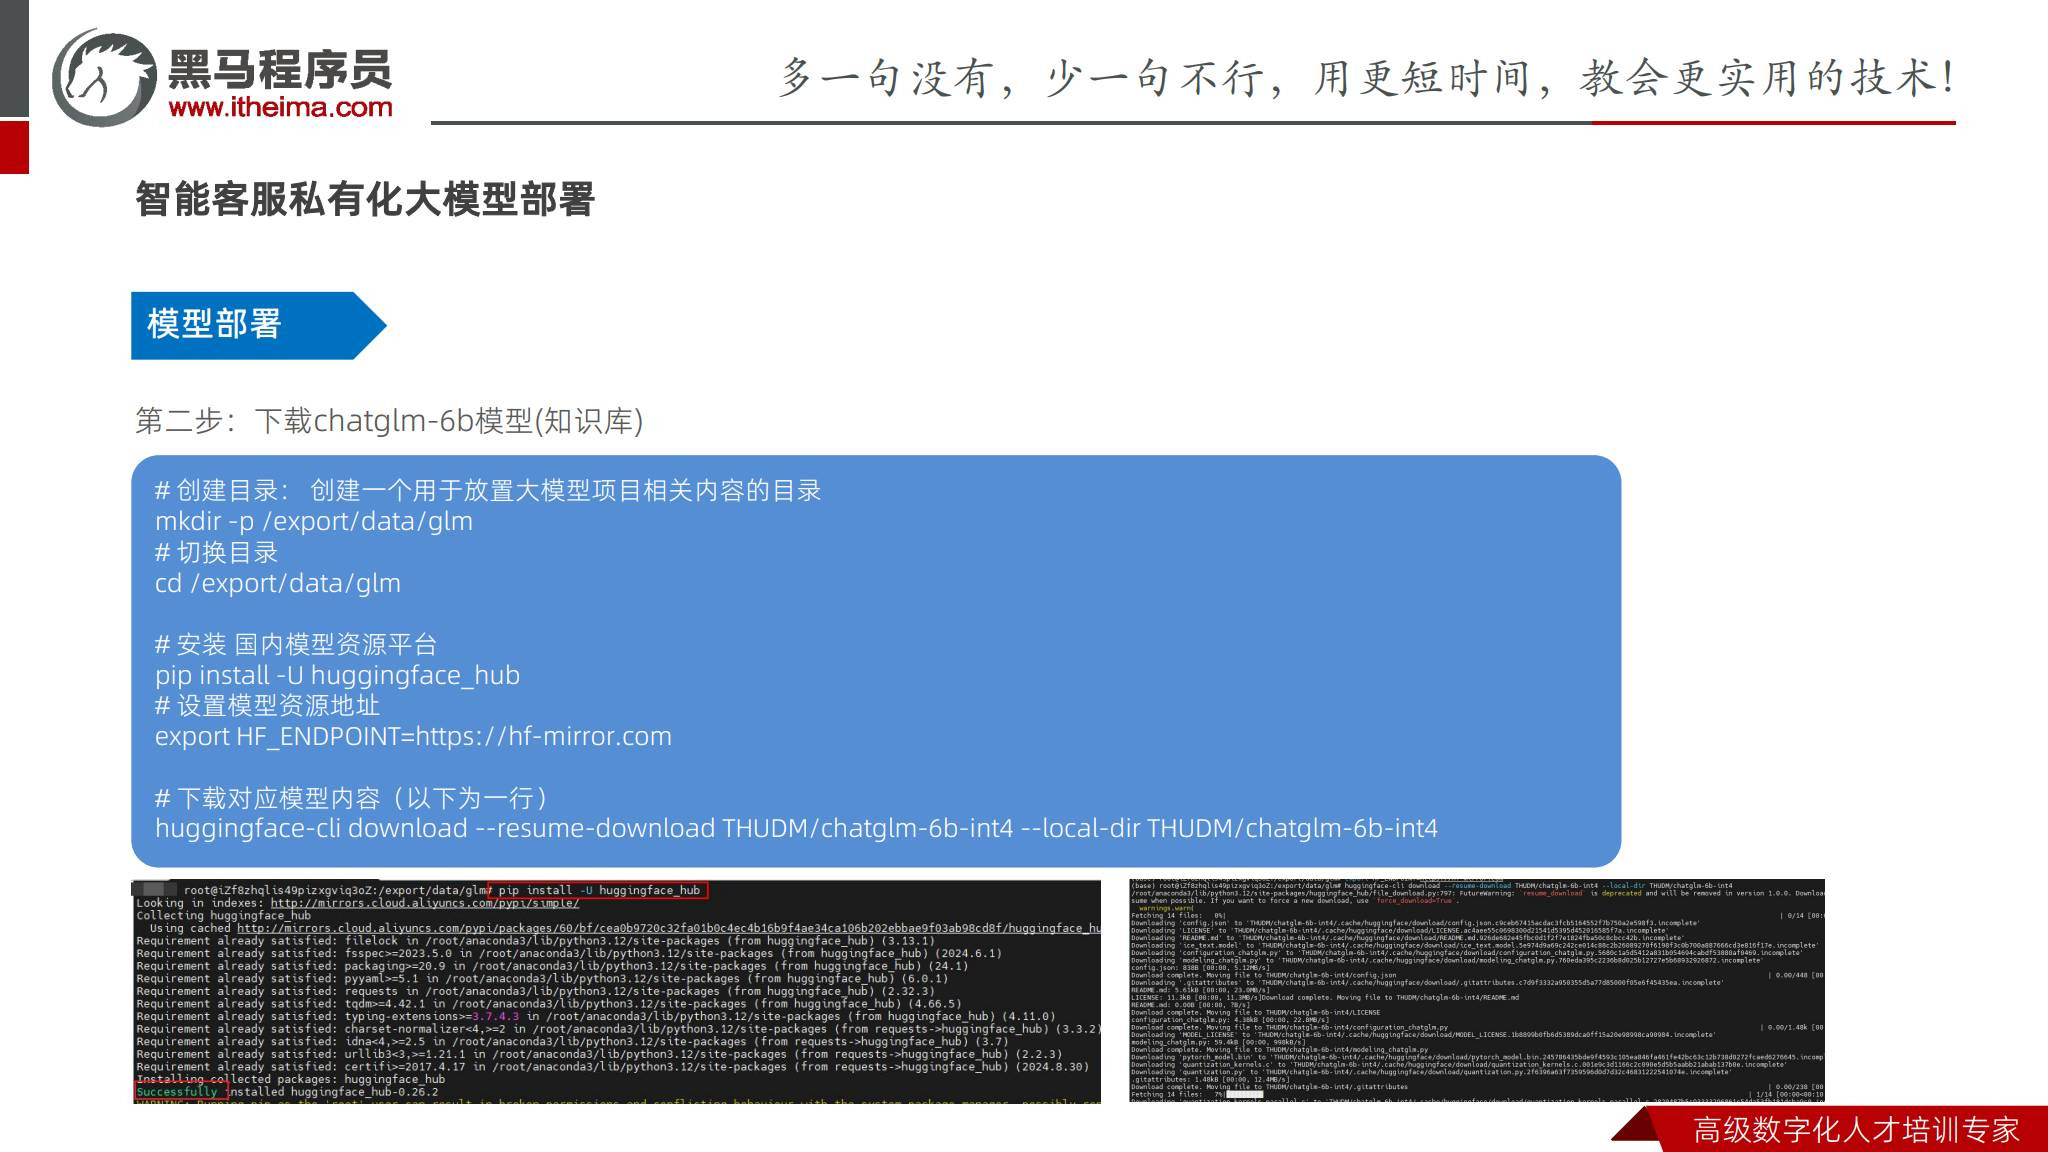

**整理补充：** 镜像的可用性、合规性和模型版本需由组织确认；生产环境应固定 revision、校验文件、限制下载源，并保存许可证和模型卡。不要把模型目录上传到 Git 或 Notebook。

### 11.2 上传代码与安装依赖

```bash
cd /export/data/glm
# 通过安全传输工具上传 ChatGLM-6B 代码
cd /export/data/glm/ChatGLM-6B
pip install -r requirements.txt -i https://mirror.sjtu.edu.cn/pypi/web/simple
```

安装依赖前检查 `requirements.txt`、Python 版本、GPU 驱动和磁盘空间。固定依赖版本并生成安装记录；镜像源故障时准备可信的备用源。课程使用的是教学示例，不代表当前项目一定能在最新依赖上运行。

### 11.3 修改模型路径

**原课依据：第 119-121 页。** 如果代码默认模型位置与实际目录不同，需要修改 `api.py` 等配置中的模型路径：

```python
# 示意：以项目实际配置项为准
MODEL_PATH = "/export/data/glm/THUDM/chatglm-6b-int4"
```

修改前先搜索所有路径引用：

```bash
grep -RIn --exclude-dir=.git 'chatglm\|MODEL_PATH\|model_path' .
python -m py_compile api.py
```

不要用相对路径依赖当前终端目录；服务启动脚本应明确工作目录和环境变量。敏感配置与模型路径分开管理，模型路径本身通常不是凭据，但目录权限仍应合理。

### 11.4 启动前验证

```bash
conda activate chatglm
python -c 'import torch; print(torch.cuda.is_available()); print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")'
du -sh /export/data/glm/THUDM/chatglm-6b-int4
nvidia-smi
```

首次启动使用脱敏测试问题，观察显存、响应耗时、上下文长度、异常堆栈和日志增长。设置超时、并发上限和进程重启策略，不要把私有模型接口直接暴露到公网。


## 十二、综合部署作业与验收

### 12.1 中州养老业务系统作业

按以下顺序完成课程练习：

1. 创建三台同可用区 ECS，完成主机名和安全组。
2. node1 安装 MySQL、Redis，导入项目 SQL 并校验。
3. 创建 OSS bucket 和最小权限访问身份，完成一张非敏感图片的上传测试。
4. 配置百度千帆测试账号和模型授权，用虚拟体检数据完成一次调用。
5. node2 安装 JDK，上传并启动后端 Jar，先本机验证，再配置成受控后台服务。
6. node3 上传 dist，配置 Nginx 静态页面和 `/prod-api/` 反向代理。
7. 从浏览器和小程序执行登录、老人信息、缴费/订单、图片和 AI 分析的最小业务链路。

### 12.2 上线前检查表

| 类别 | 检查项 |
| --- | --- |
| 版本 | Jar、dist、SQL、配置和模型都有版本或哈希 |
| 网络 | 80/443 对外；8080、3306、6379 只允许必要私网来源 |
| 凭据 | Secret 未进代码/日志/Notebook，已设置轮换和吊销 |
| 数据 | 数据库备份可恢复，OSS 生命周期和权限已核对 |
| 服务 | MySQL、Redis、后端、Nginx 启动并能自动恢复 |
| 观测 | Nginx、应用、系统、AI 调用有日志、指标和告警 |
| 回滚 | 旧 Jar、旧 dist、旧配置和数据库回滚方案已演练 |
| 隐私 | 体检报告等敏感数据有授权、脱敏、保存期限和访问审计 |

### 12.3 复习题

1. 为什么项目把 MySQL、Redis、后端 Jar 和 Nginx 分到不同节点？
2. 为什么数据库和 Redis 不应直接开放公网？
3. `mysql -u root -p < file.sql` 比把密码写在命令中安全在哪里？
4. OSS 的 bucket、对象 key 和本地文件路径有什么区别？
5. 为什么生产 CORS 不应随意使用 `Access-Control-Allow-Origin *`？
6. `java -jar` 直接启动为什么会占用当前 SSH 会话？screen 解决了什么问题？
7. Nginx 的 `try_files $uri $uri/ /index.html` 解决什么前端问题？
8. 为什么修改 `proxy_pass` 时必须注意末尾斜杠？
9. `nginx -t` 应在 reload 前做什么？
10. GPU 驱动、CUDA、PyTorch 和模型版本为什么需要一起核对？
11. 为什么 ChatGLM 环境要使用 conda 虚拟环境？
12. 模型下载为什么要固定版本、校验文件和保存许可证？


## 十三、参考答案与课件索引

| 题号 | 要点 |
| --- | --- |
| 1 | 分离职责和资源，降低相互影响，便于权限与扩容；生产还需高可用设计 |
| 2 | 减少攻击面；通过私网和安全组只允许后端访问 |
| 3 | 密码不直接出现在 shell 命令、历史和进程参数中 |
| 4 | bucket 是容器，key 是对象名称；对象访问受地域、权限和 endpoint 约束 |
| 5 | 通配来源过宽，且凭据请求不能和 `*` 安全组合 |
| 6 | Java 默认前台运行，screen 让会话与 SSH 分离；生产优先 systemd/编排 |
| 7 | 单页应用刷新深层路由时回退到 `index.html` |
| 8 | 斜杠决定代理后的 URI 拼接，错误会造成 API 路径重复或缺失 |
| 9 | 先解析配置，避免 reload 载入语法错误 |
| 10 | 不兼容会导致驱动加载失败、CUDA 错误或模型无法运行 |
| 11 | 隔离依赖，便于复现和避免不同项目互相污染 |
| 12 | 可复现、可审计、可回滚，也能确认供应链和许可边界 |

| 课件段落 | 页码 |
| --- | --- |
| 项目介绍、架构和节点总结 | 2-10 |
| ECS 初始化 | 11-17 |
| MySQL 安装和数据导入 | 18-28 |
| Redis | 29-32 |
| OSS 开通与配置 | 33-46 |
| 百度千帆授权与接入 | 47-55 |
| Java 后端与 screen | 56-65 |
| Nginx 与前端 | 66-85 |
| ChatGLM 服务器与驱动 | 86-103 |
| Anaconda、模型和代码 | 104-121 |
| 结束页 | 122 |

**本篇完成标准：** 能画出三节点架构，能解释 MySQL/Redis/OSS/千帆的职责，能按顺序描述 Jar 与 Nginx 上线，能用日志和 curl 定位常见故障，并能为 ChatGLM 部署准备相容的 GPU、驱动、Python 和模型环境。


## 附：本篇命令安全边界

Notebook 里的命令均为阅读和练习示例，不会在打开 Notebook 时自动运行。执行前替换占位符并确认当前主机、路径、权限和数据备份。涉及 `rm`、数据库导入、服务重启、密钥、公开 bucket、GPU 驱动和生产配置的命令，只能在已授权的练习或变更窗口执行。

课件中使用的具体 IP、密码、AccessKey、Secret、模型服务凭据和公网地址均不应作为真实环境配置。上线前使用组织的密钥管理、变更审批、监控告警和回滚流程。
